# CNN Feature Visualization, Parameter Audit & Critical Analysis
**Deep Learning & Computer Vision — Practical Lab Assignment**

| | |
|---|---|
| **Student Name** | Ali Sher Ahmad |
| **Registration / Roll No.** | _fill in_ |
| **Course / Section** | _fill in_ |
| **Submission Date** | _fill in_ |

**Framework:** TensorFlow 2 / Keras + NumPy + Matplotlib. Runs top-to-bottom on a free Colab CPU runtime (about 1–2 min, no GPU needed).

**Contents**
1. Setup
2. Part I: five 3×3 kernels → Conv → ReLU → MaxPool / AvgPool, plus the **5 × 4 grid**
3. Part II: Model A vs Model B, **manual parameter audit** checked against `model.summary()`
4. Part III: experiments and answers for **Questions 1–5**

All figures are saved to `outputs/` so you can put them in your report.

## 0. Setup

In [ ]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from PIL import Image, ImageDraw, ImageFont
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
pd.set_option("display.precision", 4)
print("TensorFlow", tf.__version__, "| NumPy", np.__version__)

TensorFlow 2.21.0 | NumPy 2.5.3


---
# Part I: Filter Pipeline Implementation & Visualization

## 1.1 Input image
The assignment asks for an image with **crisp horizontal and vertical edges, textures and contrast gradients**. By default the notebook draws a **synthetic building facade**. Its geometry is known exactly, so every observation in Part III can point to a specific region:

| Region | Intensity | What it tests |
|---|---|---|
| Sky (top) | smooth gradient 0.95 → 0.80 | low-frequency gradient |
| Bright cornice band (rows 48–56) | 0.90 | strong horizontal edges |
| Facade wall | 0.55 + small noise (σ = 0.02) | texture / noise |
| 3 × 4 grid of **dark windows** | 0.10 | horizontal **and** vertical edges of both polarities |
| Door (bottom centre) | 0.10 | tall vertical edges |
| Ground | 0.30 | wide horizontal edge |

> **Want to use your own photo?** Set `USE_OWN_IMAGE = True` and run the cell; Colab will ask you to upload a file. The written answers in Part III describe the default image, so if you switch, re-read your own grid and adjust the region names.

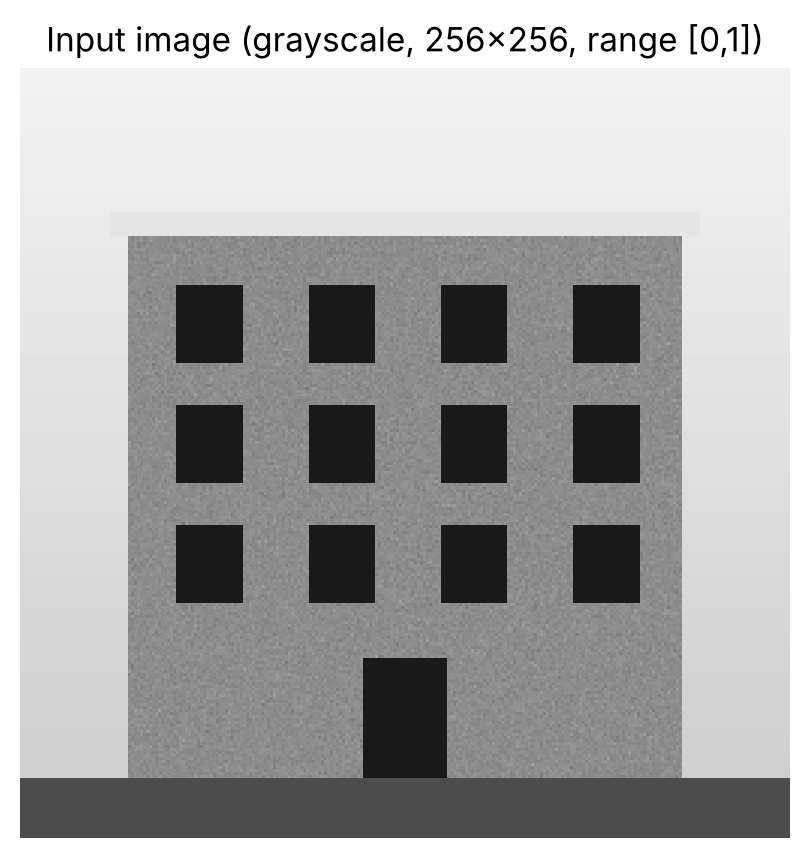

min / max / mean: 0.1 0.95 0.621


In [ ]:
USE_OWN_IMAGE = False   # set True to upload your own photo in Colab
IMG_SIZE = 256

def make_building(H=IMG_SIZE, W=IMG_SIZE, seed=SEED):
    rng = np.random.default_rng(seed)
    img = np.repeat(np.linspace(0.95, 0.80, H, dtype=np.float32)[:, None], W, axis=1)  # sky gradient
    top, bot, left, right = 48, 236, 36, 220
    img[top:bot, left:right] = 0.55 + rng.normal(0, 0.02, (bot - top, right - left))  # textured wall
    img[top:top + 8, left - 6:right + 6] = 0.90                                      # bright cornice
    for r in range(3):                                                               # 3 x 4 dark windows
        for c in range(4):
            y, x = 72 + r * 40, 52 + c * 44
            img[y:y + 26, x:x + 22] = 0.10
    img[196:bot, 114:142] = 0.10                                                     # door
    img[bot:, :] = 0.30                                                              # ground
    return np.clip(img, 0, 1).astype(np.float32)

if USE_OWN_IMAGE:
    from google.colab import files
    uploaded = files.upload()
    fname = next(iter(uploaded))
    img = np.asarray(Image.open(fname).convert("L").resize((IMG_SIZE, IMG_SIZE)), np.float32) / 255.0
else:
    img = make_building()

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title(f"Input image (grayscale, {img.shape[0]}×{img.shape[1]}, range [0,1])")
plt.axis("off"); plt.savefig(f"{OUT}/00_input_image.png", dpi=150, bbox_inches="tight"); plt.show()
print("min / max / mean:", img.min().round(3), img.max().round(3), img.mean().round(3))

## 1.2 Five custom 3×3 kernels

| # | Kernel | Matrix | What it responds to |
|---|---|---|---|
| 1 | **Horizontal edge** (Sobel) | `[[-1,-2,-1],[0,0,0],[1,2,1]]` | intensity change **top → bottom** (horizontal edges) |
| 2 | **Vertical edge** (Sobel) | `[[-1,0,1],[-2,0,2],[-1,0,1]]` | intensity change **left → right** (vertical edges) |
| 3 | **Sharpen** | `[[0,-1,0],[-1,5,-1],[0,-1,0]]` | boosts the centre pixel against its neighbours |
| 4 | **Gaussian blur** | `[[1,2,1],[2,4,2],[1,2,1]] / 16` | low-pass smoothing (weights sum to 1) |
| 5 | **Emboss** | `[[-2,-1,0],[-1,1,1],[0,1,2]]` | directional diagonal relief (top-left → bottom-right) |

> **Note on naming (likely viva question):** books disagree on which Sobel kernel is "X" and which is "Y". The kernel that computes the **x-gradient** (`[[-1,0,1],…]`) responds to **vertical** edges, and the y-gradient kernel responds to **horizontal** edges. This notebook names each filter by the **edge orientation it detects**, which is what the assignment's "Horizontal / Vertical Edge Detector" labels mean.

> **Implementation detail:** `tf.nn.conv2d` computes **cross-correlation**, so the kernel is not flipped. The image is **reflect-padded** by 1 pixel before a `VALID` convolution. The output stays 256 × 256, and the bright fake edges that zero padding would create at the image border are avoided.

In [ ]:
KERNELS = {
    "Horizontal Edge": np.array([[-1, -2, -1],
                                 [ 0,  0,  0],
                                 [ 1,  2,  1]], np.float32),
    "Vertical Edge":   np.array([[-1,  0,  1],
                                 [-2,  0,  2],
                                 [-1,  0,  1]], np.float32),
    "Sharpen":         np.array([[ 0, -1,  0],
                                 [-1,  5, -1],
                                 [ 0, -1,  0]], np.float32),
    "Gaussian Blur":   np.array([[1, 2, 1],
                                 [2, 4, 2],
                                 [1, 2, 1]], np.float32) / 16.0,
    "Emboss":          np.array([[-2, -1, 0],
                                 [-1,  1, 1],
                                 [ 0,  1, 2]], np.float32),
}
for name, k in KERNELS.items():
    print(f"{name:16s} sum of weights = {k.sum():+.2f}\n{k}\n")

Horizontal Edge  sum of weights = +0.00
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

Vertical Edge    sum of weights = +0.00
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Sharpen          sum of weights = +1.00
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Gaussian Blur    sum of weights = +1.00
[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]

Emboss           sum of weights = +1.00
[[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]]



## 1.3 Sequential layer execution (Stages A → D)
For each filter separately:
- **Stage A**: raw convolution output (linear, can be negative)
- **Stage B**: `ReLU(A) = max(0, A)`
- **Stage C**: `MaxPool2D(2×2, stride 2)` applied to B → 128 × 128
- **Stage D**: `AvgPool2D(2×2, stride 2)` applied to B → 128 × 128

In [ ]:
def to4d(x):            # (H,W) -> (1,H,W,1) as TF expects NHWC
    return tf.convert_to_tensor(x[None, ..., None], tf.float32)

def conv_same(image, kernel):
    padded = np.pad(image, 1, mode="reflect")
    w = tf.convert_to_tensor(kernel[..., None, None], tf.float32)    # (3,3,in=1,out=1)
    return tf.nn.conv2d(to4d(padded), w, strides=1, padding="VALID")[0, ..., 0].numpy()

def relu(x):     return tf.nn.relu(x).numpy()
def maxpool(x):  return tf.nn.max_pool2d(to4d(x), ksize=2, strides=2, padding="VALID")[0, ..., 0].numpy()
def avgpool(x):  return tf.nn.avg_pool2d(to4d(x), ksize=2, strides=2, padding="VALID")[0, ..., 0].numpy()

stages = {}
for name, k in KERNELS.items():
    A = conv_same(img, k)
    B = relu(A)
    C = maxpool(B)
    D = avgpool(B)
    stages[name] = {"A": A, "B": B, "C": C, "D": D}

rows = []
for name, s in stages.items():
    A, B, C, D = s["A"], s["B"], s["C"], s["D"]
    rows.append({
        "Filter": name,
        "A shape": str(A.shape), "C/D shape": str(C.shape),
        "A min": A.min(), "A max": A.max(),
        "% A < 0": 100 * (A < 0).mean(),
        "% B == 0 (ReLU blackout)": 100 * (B == 0).mean(),
        "B mean": B.mean(), "C mean (max)": C.mean(), "D mean (avg)": D.mean(),
        "C peak": C.max(), "D peak": D.max(),
    })
stats = pd.DataFrame(rows).set_index("Filter")
stats.to_csv(f"{OUT}/part1_stage_statistics.csv")
stats

,A shape,C/D shape,A min,A max,% A < 0,% B == 0 (ReLU blackout),B mean,C mean (max),D mean (avg),C peak,D peak
Filter,,,,,,,,,,,
Horizontal Edge,"(256, 256)","(128, 128)",-2.0494,1.9216,70.1065,77.5284,0.0255,0.0555,0.0255,1.9216,0.9893
Vertical Edge,"(256, 256)","(128, 128)",-1.9569,1.9458,20.5978,79.2587,0.0366,0.0775,0.0366,1.9458,0.9856
Sharpen,"(256, 256)","(128, 128)",-0.8848,1.5693,2.0218,2.0218,0.6285,0.6902,0.6285,1.5693,1.2023
Gaussian Blur,"(256, 256)","(128, 128)",0.1000,0.9497,0.0000,0.0000,0.6214,0.6295,0.6214,0.9497,0.9496
Emboss,"(256, 256)","(128, 128)",-1.8434,2.0942,3.6469,3.6469,0.6323,0.7057,0.6323,2.0942,1.4689


## 1.4 The 5 × 4 comparative visualization grid
**Intensity scaling is consistent within each row:**
- Stage A uses a symmetric range `[-m, +m]` (where `m = max|A|` for that filter), so **mid-grey = 0**, darker = negative and brighter = positive. Filters with no negative output (blur) use `[0, m]`.
- Stages B, C and D share the range `[0, m]`, so **pure black = exactly 0** (the ReLU blackout) and brightness can be compared directly across B, C and D.

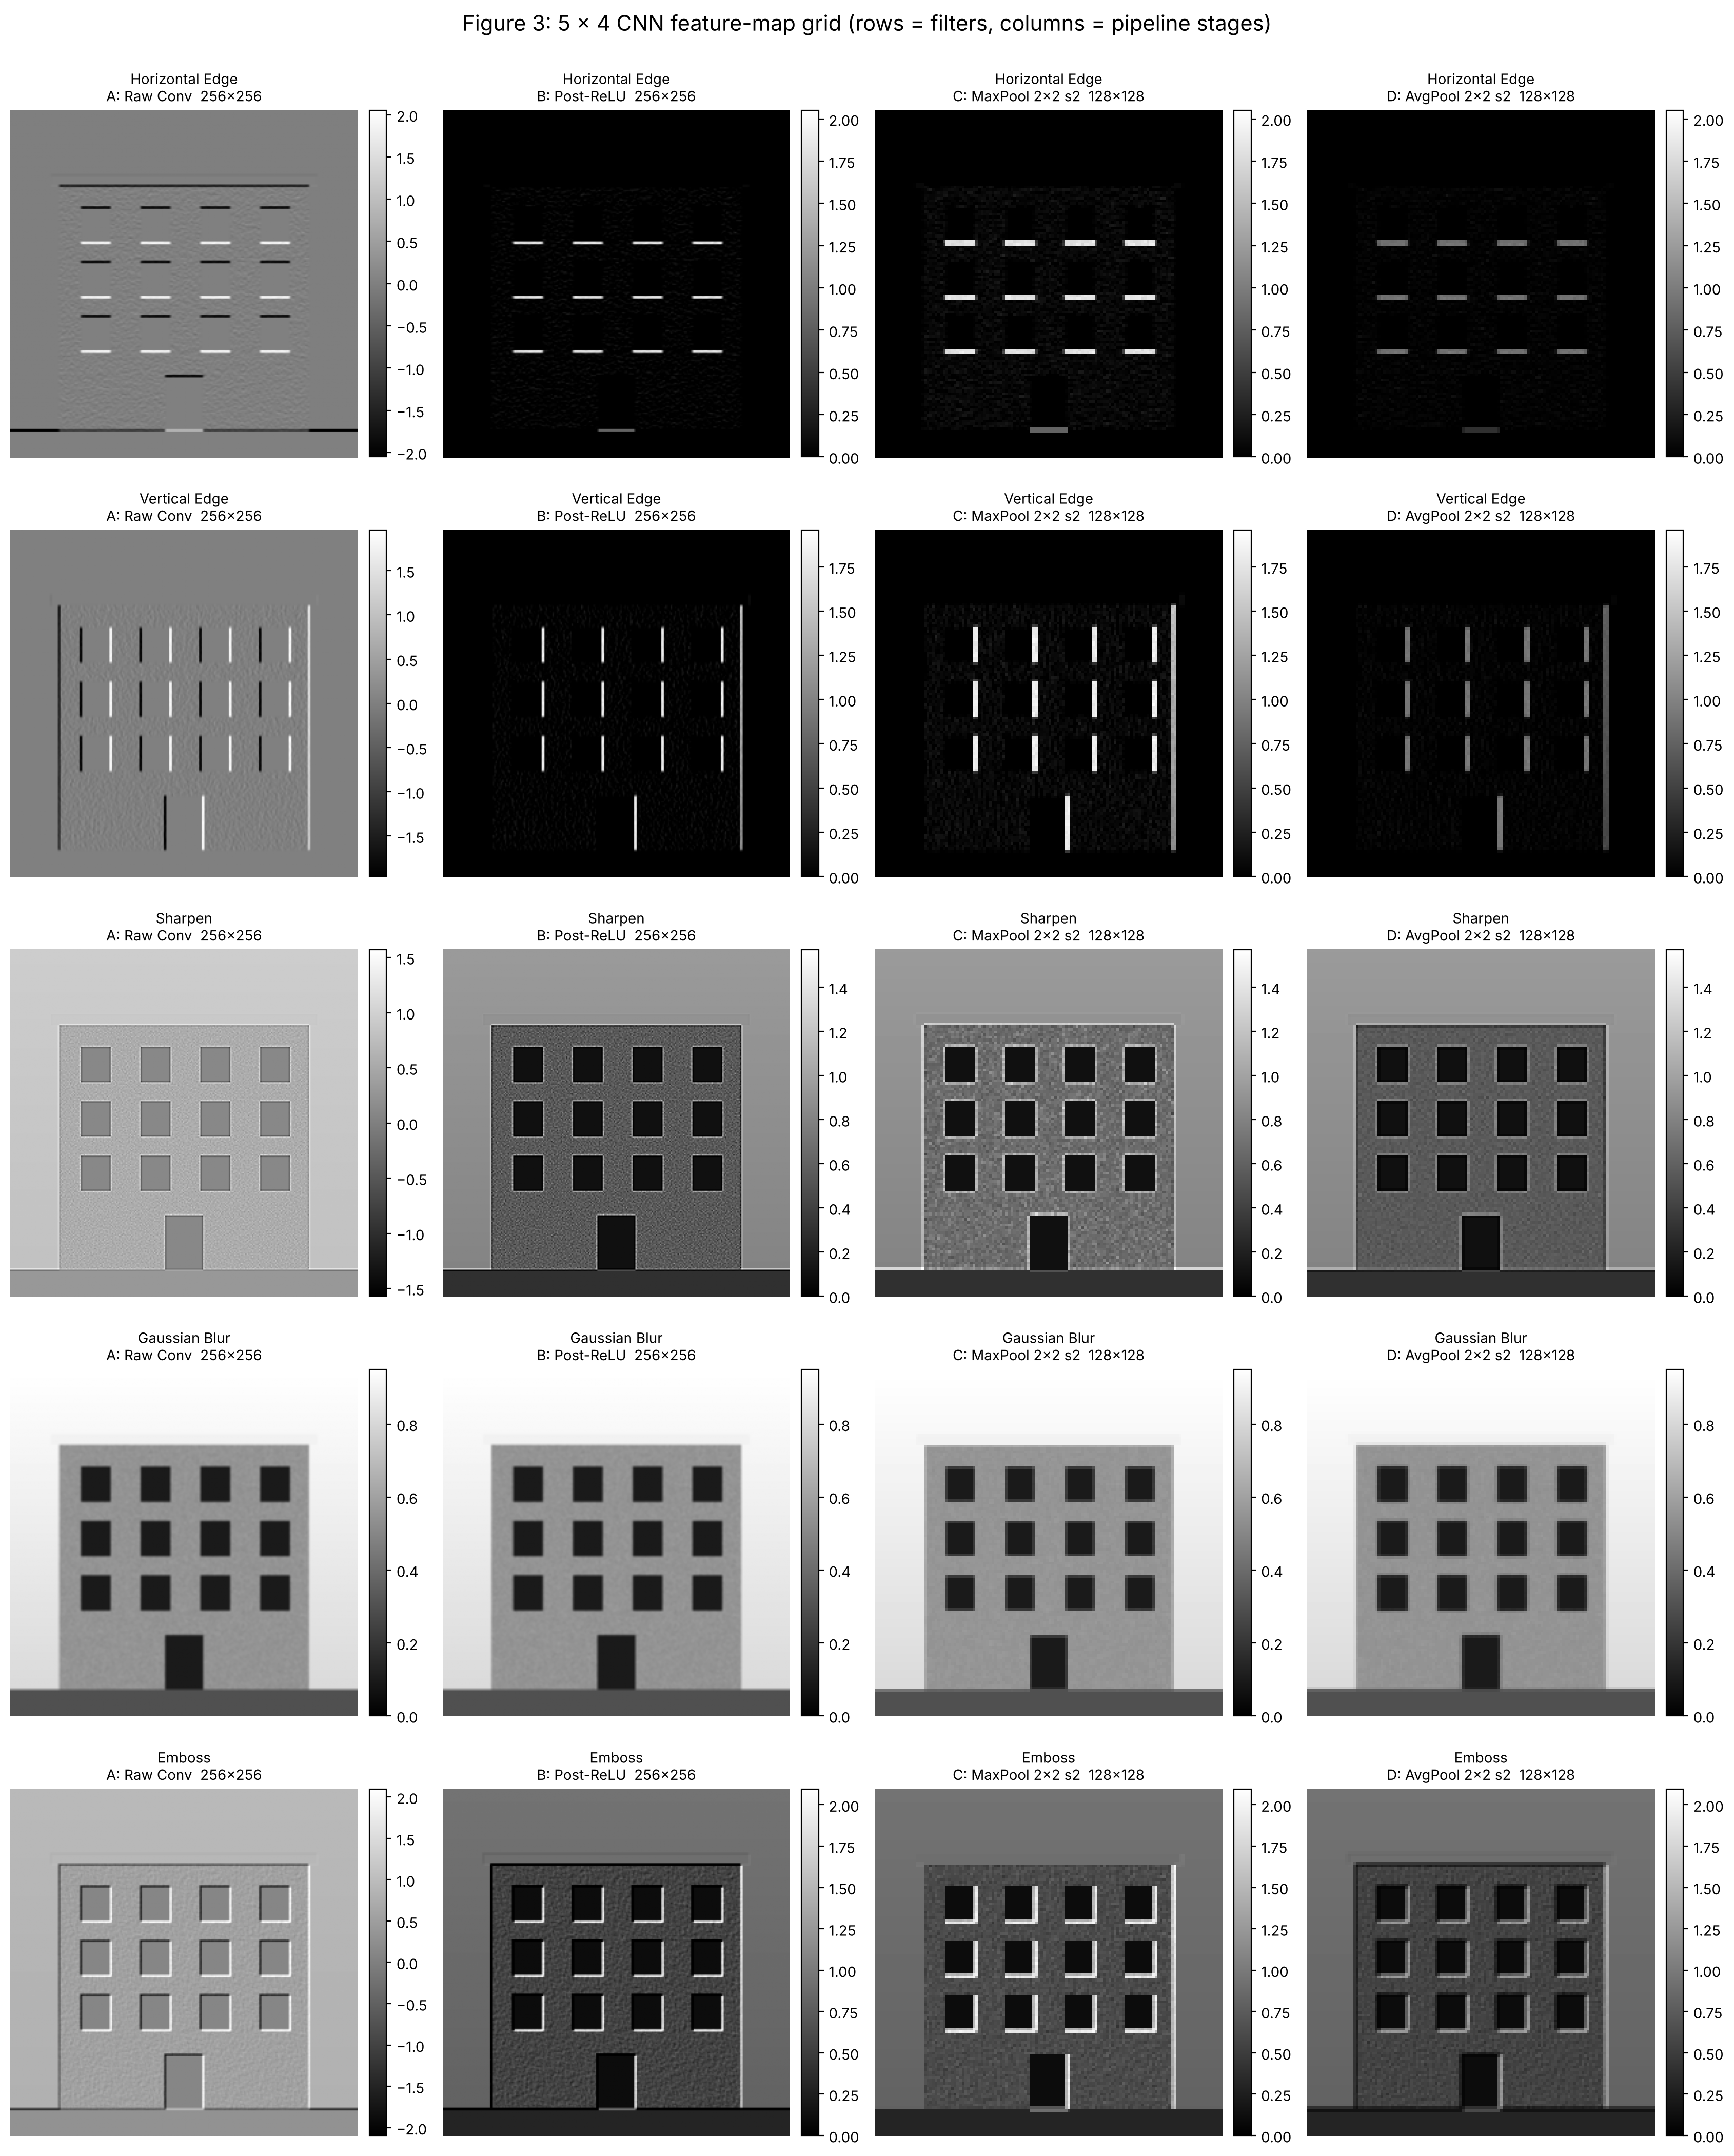

In [ ]:
STAGE_TITLES = {"A": "A: Raw Conv", "B": "B: Post-ReLU",
                "C": "C: MaxPool 2×2 s2", "D": "D: AvgPool 2×2 s2"}

fig, axes = plt.subplots(5, 4, figsize=(17, 21))
for i, (name, s) in enumerate(stages.items()):
    m = np.abs(s["A"]).max()
    vminA = -m if s["A"].min() < 0 else 0.0
    for j, key in enumerate("ABCD"):
        ax = axes[i, j]
        vmin, vmax = (vminA, m) if key == "A" else (0.0, m)
        im = ax.imshow(s[key], cmap="gray", vmin=vmin, vmax=vmax)
        ax.set_title(f"{name}\n{STAGE_TITLES[key]}  {s[key].shape[0]}×{s[key].shape[1]}", fontsize=10)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle("Figure 3: 5 × 4 CNN feature-map grid (rows = filters, columns = pipeline stages)",
             fontsize=15, y=1.0)
plt.tight_layout()
plt.savefig(f"{OUT}/01_feature_grid_5x4.png", dpi=150, bbox_inches="tight")
plt.show()

---
# Part II: Architectural Comparison & Parameter Audit

**Architecture (both models):**
`Input 32×32×3 → Conv1 (5 filters) + ReLU → Pool 2×2/2 → Conv2 (10 filters) + ReLU → Pool 2×2/2 → GlobalAveragePooling → Dense(10, softmax)`

- Model A: 3×3 kernels with **Max** pooling
- Model B: 5×5 kernels with **Avg** pooling

## 2.1 Manual calculation (done before running `model.summary()`)

Formula: **Params = (K_h × K_w × C_in + 1) × C_out**. The "+1" is the bias of each filter.
Pooling and Global Average Pooling have **0** parameters, and padding does not change the count.
Dense layer: **(inputs + 1) × outputs**.

### Model A (3×3, Max Pool)
| Layer | Calculation | Params |
|---|---|---|
| Conv1 | (3 × 3 × **3** + 1) × 5 = (27 + 1) × 5 | **140** |
| MaxPool | no weights | 0 |
| Conv2 | (3 × 3 × **5** + 1) × 10 = (45 + 1) × 10 | **460** |
| MaxPool + GAP | no weights | 0 |
| Dense | (10 + 1) × 10 | **110** |
| **Total** | 140 + 460 + 110 | **710** |

### Model B (5×5, Avg Pool)
| Layer | Calculation | Params |
|---|---|---|
| Conv1 | (5 × 5 × **3** + 1) × 5 = (75 + 1) × 5 | **380** |
| AvgPool | no weights | 0 |
| Conv2 | (5 × 5 × **5** + 1) × 10 = (125 + 1) × 10 | **1 260** |
| AvgPool + GAP | no weights | 0 |
| Dense | (10 + 1) × 10 | **110** |
| **Total** | 380 + 1260 + 110 | **1 750** |

Conv2's C_in is **5**, the number of filters in Conv1, not 3. Pooling changes the spatial size but never the channel count. GAP turns 8×8×10 into a 10-vector, which is why the Dense layer has 10 inputs.

In [ ]:
from tensorflow.keras import layers, models

def build_model(kernel, pool, name):
    Pool = layers.MaxPooling2D if pool == "max" else layers.AveragePooling2D
    return models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(5,  kernel, padding="same", activation="relu", name="conv1"),
        Pool(pool_size=2, strides=2, name=f"{pool}pool1"),
        layers.Conv2D(10, kernel, padding="same", activation="relu", name="conv2"),
        Pool(pool_size=2, strides=2, name=f"{pool}pool2"),
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(10, activation="softmax", name="dense_out"),
    ], name=name)

model_A = build_model((3, 3), "max", "Model_A_Standard_3x3_MaxPool")
model_B = build_model((5, 5), "avg", "Model_B_LargeKernel_5x5_AvgPool")
model_A.summary()

Model: "Model_A_Standard_3x3_MaxPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool1 (MaxPooling2D)         │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool2 (MaxPooling2D)         │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_B.summary()

Model: "Model_B_LargeKernel_5x5_AvgPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avgpool1 (AveragePooling2D)     │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avgpool2 (AveragePooling2D)     │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

## 2.2 Audit table: manual count vs. framework output

In [ ]:
def conv_params(kh, kw, cin, cout):  return (kh * kw * cin + 1) * cout
def dense_params(nin, nout):         return (nin + 1) * nout

def manual_total(k):
    return conv_params(k, k, 3, 5) + conv_params(k, k, 5, 10) + dense_params(10, 10)

def trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

audit = pd.DataFrame([
    {"Model": "Model A (Standard)", "Conv Architecture": "Conv1: 5 filters, Conv2: 10 filters",
     "Kernel": "3×3", "Pooling": "Max (2×2, s2)",
     "Conv1": conv_params(3, 3, 3, 5), "Conv2": conv_params(3, 3, 5, 10), "Dense": dense_params(10, 10),
     "Manual Count": manual_total(3), "Code Output": trainable(model_A)},
    {"Model": "Model B (Large Kernel)", "Conv Architecture": "Conv1: 5 filters, Conv2: 10 filters",
     "Kernel": "5×5", "Pooling": "Avg (2×2, s2)",
     "Conv1": conv_params(5, 5, 3, 5), "Conv2": conv_params(5, 5, 5, 10), "Dense": dense_params(10, 10),
     "Manual Count": manual_total(5), "Code Output": trainable(model_B)},
])
audit["Match"] = np.where(audit["Manual Count"] == audit["Code Output"], "✅", "❌")
audit.to_csv(f"{OUT}/part2_parameter_audit.csv", index=False)

# per-layer check straight from Keras
for m in (model_A, model_B):
    print(m.name)
    for l in m.layers:
        print(f"   {l.name:12s} output {str(l.output.shape):18s} params {l.count_params()}")
audit

Model_A_Standard_3x3_MaxPool
   conv1        output (None, 32, 32, 5)  params 140
   maxpool1     output (None, 16, 16, 5)  params 0
   conv2        output (None, 16, 16, 10) params 460
   maxpool2     output (None, 8, 8, 10)   params 0
   gap          output (None, 10)         params 0
   dense_out    output (None, 10)         params 110
Model_B_LargeKernel_5x5_AvgPool
   conv1        output (None, 32, 32, 5)  params 380
   avgpool1     output (None, 16, 16, 5)  params 0
   conv2        output (None, 16, 16, 10) params 1260
   avgpool2     output (None, 8, 8, 10)   params 0
   gap          output (None, 10)         params 0
   dense_out    output (None, 10)         params 110


,Model,Conv Architecture,Kernel,Pooling,Conv1,Conv2,Dense,Manual Count,Code Output,Match
0,Model A (Standard),"Conv1: 5 filters, Conv2: 10 filters",3×3,"Max (2×2, s2)",140,460,110,710,710,✅
1,Model B (Large Kernel),"Conv1: 5 filters, Conv2: 10 filters",5×5,"Avg (2×2, s2)",380,1260,110,1750,1750,✅


---
# Part III: Critical Thinking & Viva Defense

Each question has an **experiment cell** that produces evidence from the feature maps above, followed by a written **answer** that cites that evidence.

## Question 1: The ReLU "Blackout" Effect & Activation Alternatives
Zoom in on one window (top-left window, rows 72–97, cols 52–73), then compare ReLU with Leaky ReLU (α = 0.1) and Sigmoid on the same raw maps.

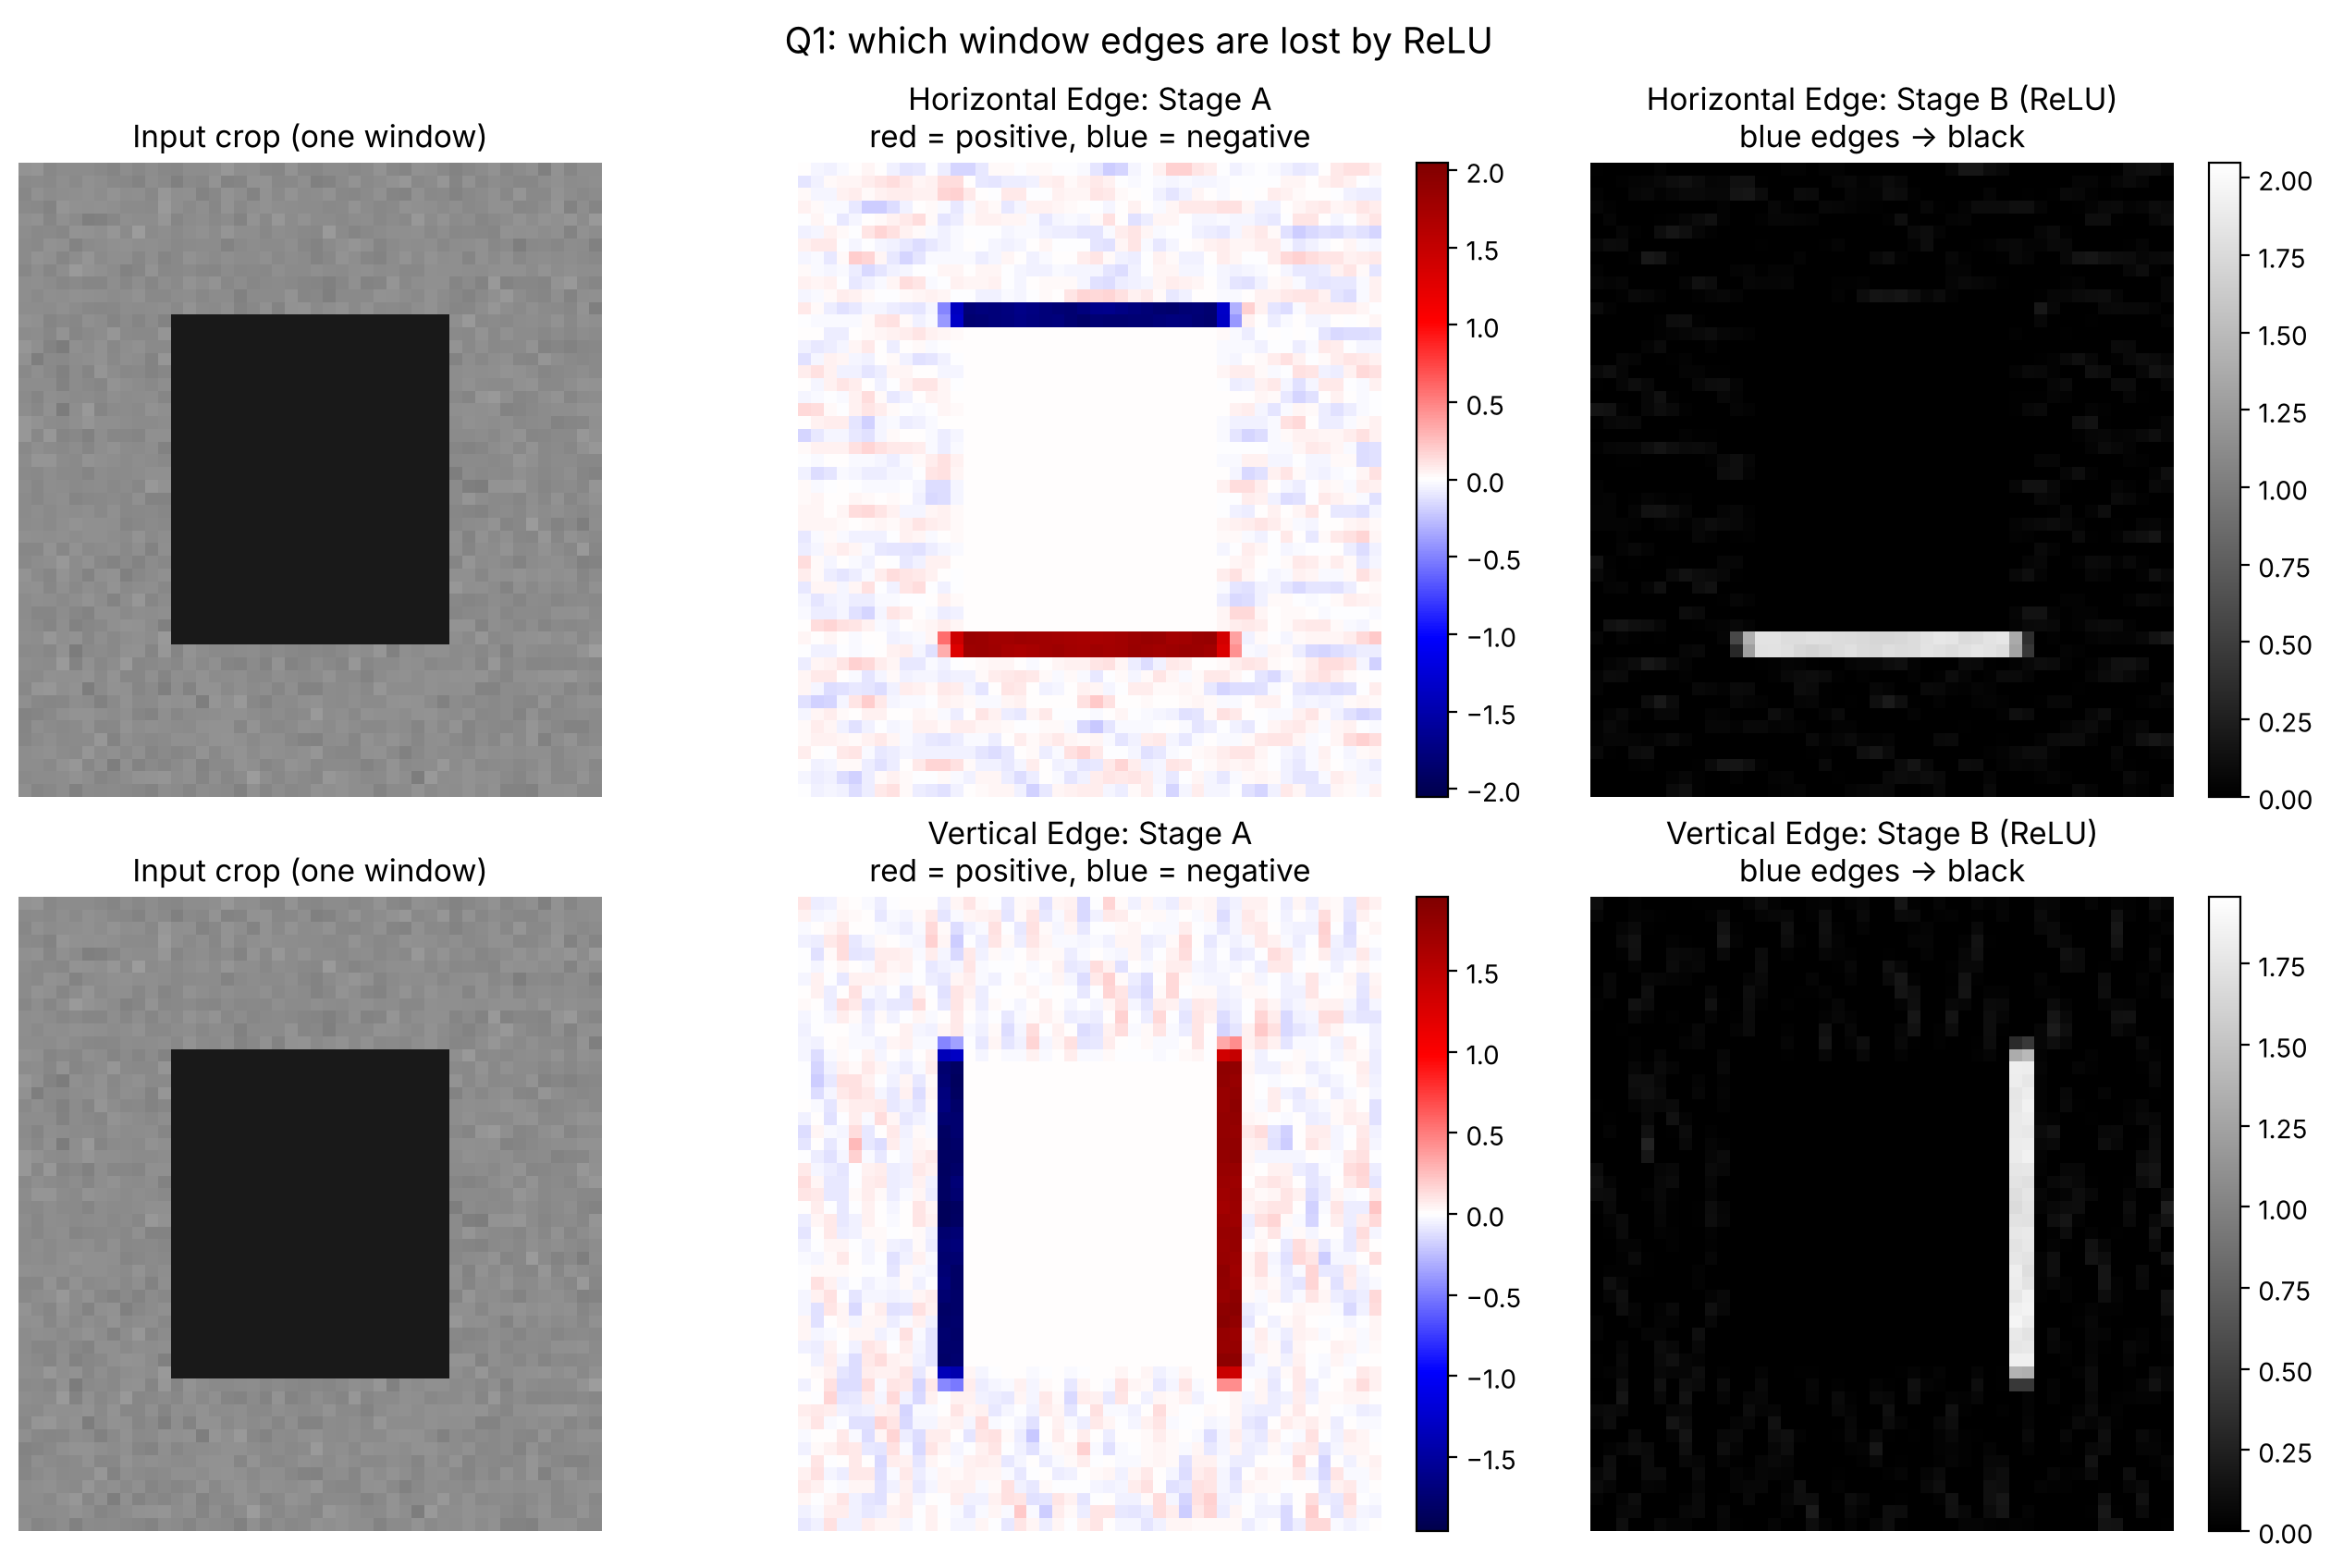

Horizontal Edge, Stage A, value on window TOP edge   (row 71/72): -1.783
Horizontal Edge, Stage A, value on window BOTTOM edge(row 97/98): 1.769
Vertical Edge,   Stage A, value on window LEFT edge  (col 51/52): -1.79
Vertical Edge,   Stage A, value on window RIGHT edge (col 73/74): 1.773
Horizontal Edge: 70.1% of pixels negative before ReLU, 77.5% exactly zero after ReLU
Vertical Edge: 20.6% of pixels negative before ReLU, 79.3% exactly zero after ReLU


In [ ]:
y0, y1, x0, x1 = 60, 110, 40, 86          # crop around the top-left window
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for i, name in enumerate(["Horizontal Edge", "Vertical Edge"]):
    A = stages[name]["A"]; m = np.abs(A).max()
    axes[i, 0].imshow(img[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=1); axes[i, 0].set_title("Input crop (one window)")
    im1 = axes[i, 1].imshow(A[y0:y1, x0:x1], cmap="seismic", vmin=-m, vmax=m)
    axes[i, 1].set_title(f"{name}: Stage A\nred = positive, blue = negative")
    im2 = axes[i, 2].imshow(relu(A)[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=m)
    axes[i, 2].set_title(f"{name}: Stage B (ReLU)\nblue edges -> black")
    fig.colorbar(im1, ax=axes[i, 1], fraction=0.046); fig.colorbar(im2, ax=axes[i, 2], fraction=0.046)
    for ax in axes[i]: ax.axis("off")
plt.suptitle("Q1: which window edges are lost by ReLU", fontsize=14)
plt.tight_layout(); plt.savefig(f"{OUT}/q1_relu_blackout_zoom.png", dpi=150, bbox_inches="tight"); plt.show()

# numeric evidence on the window edges (row/col indices are known from make_building)
H, V = stages["Horizontal Edge"]["A"], stages["Vertical Edge"]["A"]
wy, wx = 72, 52        # window top-left corner; window is 26 tall x 22 wide
print("Horizontal Edge, Stage A, value on window TOP edge   (row 71/72):", H[wy-1:wy+1, wx+5:wx+17].mean().round(3))
print("Horizontal Edge, Stage A, value on window BOTTOM edge(row 97/98):", H[wy+25:wy+27, wx+5:wx+17].mean().round(3))
print("Vertical Edge,   Stage A, value on window LEFT edge  (col 51/52):", V[wy+5:wy+21, wx-1:wx+1].mean().round(3))
print("Vertical Edge,   Stage A, value on window RIGHT edge (col 73/74):", V[wy+5:wy+21, wx+21:wx+23].mean().round(3))
for name in ["Horizontal Edge", "Vertical Edge"]:
    A = stages[name]["A"]
    print(f"{name}: {100*(A<0).mean():.1f}% of pixels negative before ReLU, "
          f"{100*(relu(A)==0).mean():.1f}% exactly zero after ReLU")

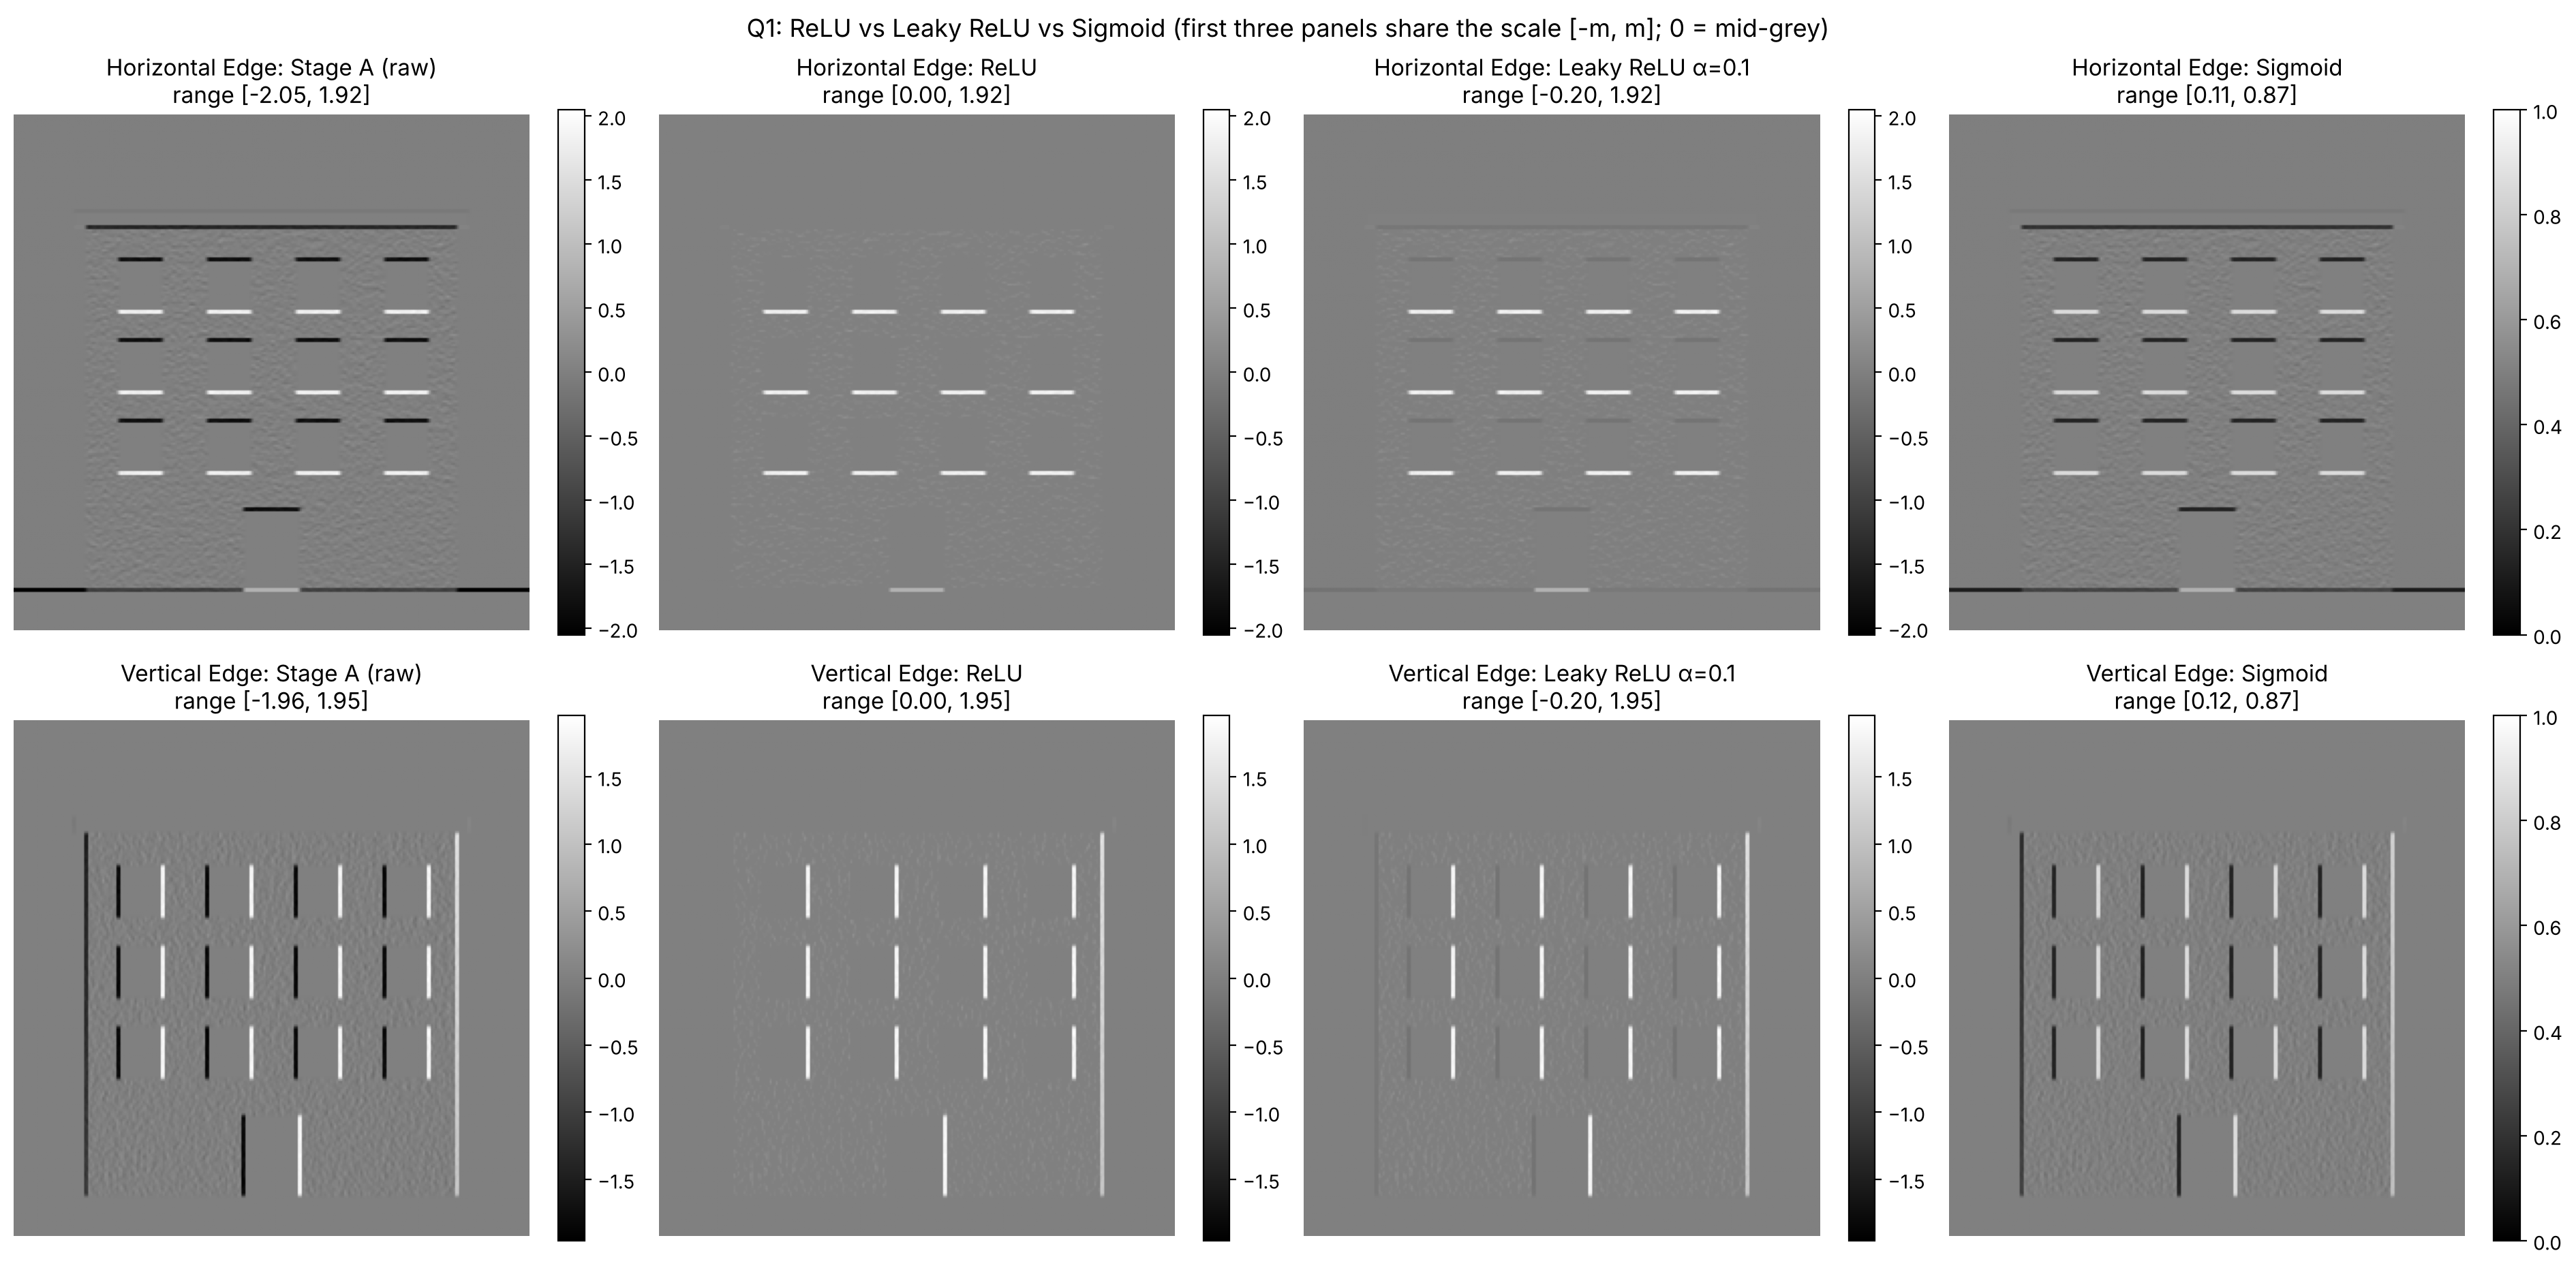

Flat wall pixel (A≈0):  ReLU -> 0,  Leaky -> ≈0,  Sigmoid -> 0.5
Window top edge (A=-1.82): ReLU -> 0,  Leaky -> -0.182,  Sigmoid -> 0.140
Window bottom edge (A=1.76): ReLU -> 1.757, Leaky -> 1.757, Sigmoid -> 0.853


In [ ]:
def leaky_relu(x, a=0.1): return np.where(x > 0, x, a * x)
def sigmoid(x):           return 1.0 / (1.0 + np.exp(-x))

fig, axes = plt.subplots(2, 4, figsize=(19, 9.5))
for i, name in enumerate(["Horizontal Edge", "Vertical Edge"]):
    A = stages[name]["A"]; m = np.abs(A).max()
    panels = [("Stage A (raw)", A, -m, m),
              ("ReLU", relu(A), -m, m),
              ("Leaky ReLU α=0.1", leaky_relu(A), -m, m),
              ("Sigmoid", sigmoid(A), 0, 1)]
    for j, (t, X, lo, hi) in enumerate(panels):
        im = axes[i, j].imshow(X, cmap="gray", vmin=lo, vmax=hi)
        axes[i, j].set_title(f"{name}: {t}\nrange [{X.min():.2f}, {X.max():.2f}]")
        axes[i, j].axis("off"); fig.colorbar(im, ax=axes[i, j], fraction=0.046)
plt.suptitle("Q1: ReLU vs Leaky ReLU vs Sigmoid (first three panels share the scale [-m, m]; 0 = mid-grey)", fontsize=13)
plt.tight_layout(); plt.savefig(f"{OUT}/q1_activation_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

A = stages["Horizontal Edge"]["A"]
print("Flat wall pixel (A≈0):  ReLU -> 0,  Leaky -> ≈0,  Sigmoid ->", sigmoid(np.float32(0.0)))
print("Window top edge (A=%.2f): ReLU -> 0,  Leaky -> %.3f,  Sigmoid -> %.3f"
      % (A[71, 60], leaky_relu(A[71, 60]), sigmoid(A[71, 60])))
print("Window bottom edge (A=%.2f): ReLU -> %.3f, Leaky -> %.3f, Sigmoid -> %.3f"
      % (A[97, 60], relu(A[97, 60]), leaky_relu(A[97, 60]), sigmoid(A[97, 60])))

### ✍️ Answer Q1: the ReLU "blackout"

**What turned black (Stage A → Stage B).** Both edge kernels produce **equal and opposite** responses on the two sides of every dark object. ReLU deletes the negative side.

| Row | Region that goes **black** after ReLU | Stage A value | Region that **survives** | Stage A value |
|---|---|---|---|---|
| Horizontal Edge | **top edge of every window**, top of the door, underside of the bright cornice, wall→ground line, and the whole sky | ≈ **−1.78** | **bottom edge** of every window, door→ground line | ≈ **+1.77** |
| Vertical Edge | **left edge of every window** and of the door, plus the building's **left outer wall** | ≈ **−1.79** | **right edge** of windows, door and the building's right wall | ≈ **+1.77** |

In numbers: **70.1 %** of Horizontal-Edge pixels are negative in Stage A, and **77.5 %** are exactly 0 in Stage B. For the Vertical Edge it is **20.6 %** negative and **79.3 %** zero. Zero-padding is not involved because the image was reflect-padded.

**Why those pixels were negative.** In cross-correlation the horizontal Sobel kernel computes
`out = (row below: 1·a + 2·b + 1·c) − (row above: 1·d + 2·e + 1·f)`, so it measures **how much brighter the image gets moving downward**.
- At the **top edge of a window** the image goes from bright wall (0.55) to dark glass (0.10) moving down: 4 × (0.10 − 0.55) ≈ **−1.8**, which is negative, so ReLU makes it 0.
- At the **bottom edge** it goes dark → bright: 4 × (0.55 − 0.10) ≈ **+1.8**, which survives.
- The **sky** darkens slightly with every row (0.95 → 0.80), giving a tiny negative value everywhere (≈ −0.002). That is why 70 % of the Horizontal map is negative even though only a few lines are visible.
- The vertical kernel does the same thing left → right, so the **left** sides of windows (wall → glass) are negative.

ReLU keeps only **one polarity** of each edge (dark→bright transitions). This is why real CNNs learn **pairs of filters with opposite sign**, or use activations that keep negative information.

**If ReLU were replaced (see `q1_activation_comparison.png`):**
- **Leaky ReLU (α = 0.1)**, `f(x) = x if x > 0 else 0.1x`. The positive edges are unchanged (+1.76 → 1.76). The negative edges are kept at 10 % strength (−1.82 → **−0.18**), so the top and left window edges appear as **faint dark lines just below mid-grey** instead of disappearing. The map is no longer sparse (almost no exact zeros), and the gradient on the negative side is 0.1 instead of 0, so those neurons can still learn.
- **Sigmoid**, `σ(x) = 1/(1+e^{−x})`. Zero maps to **0.5**, so the whole flat wall and sky turn **mid-grey** instead of black. Negative edges map to ≈ **0.14** (dark lines) and positive edges to ≈ **0.85** (bright lines). Both polarities survive, but everything is squashed into (0, 1). There is **no sparsity**, the output is **not zero-centred**, and the gradient σ′(x) ≤ 0.25 vanishes for large |x|. That is why sigmoid is a poor choice for hidden conv layers.

## Question 2: Max Pooling vs. Average Pooling Information Retention

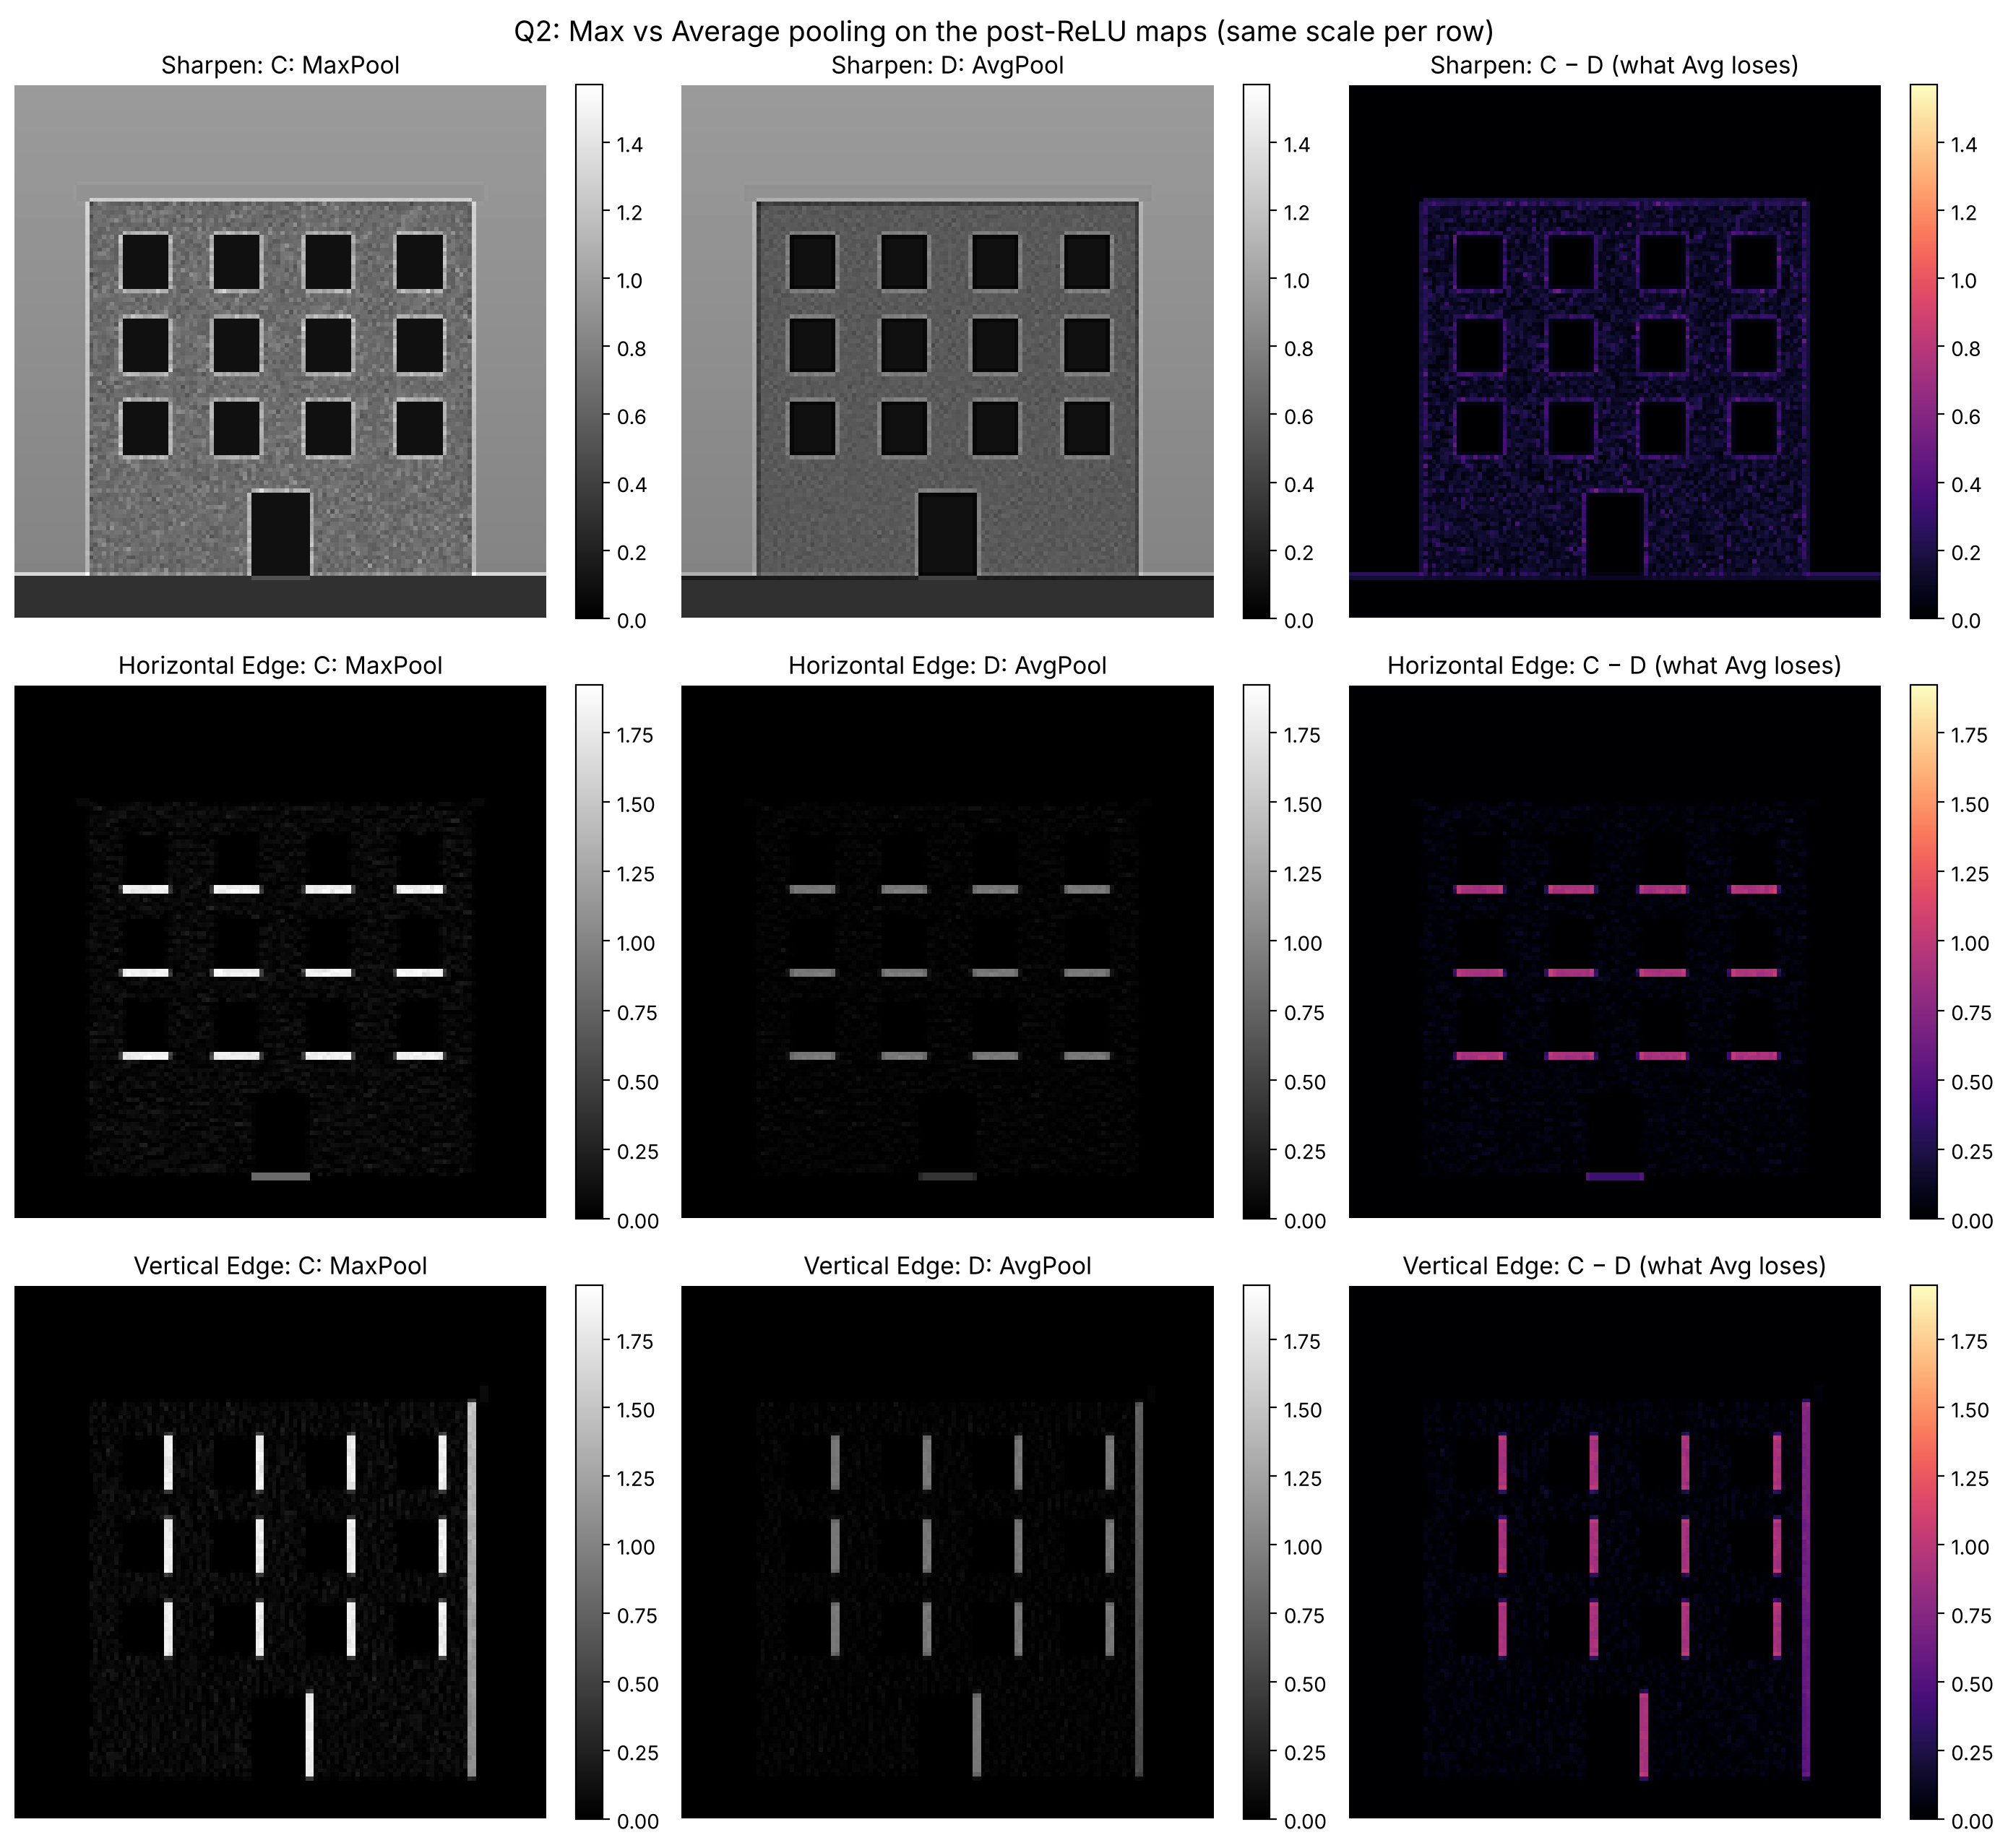

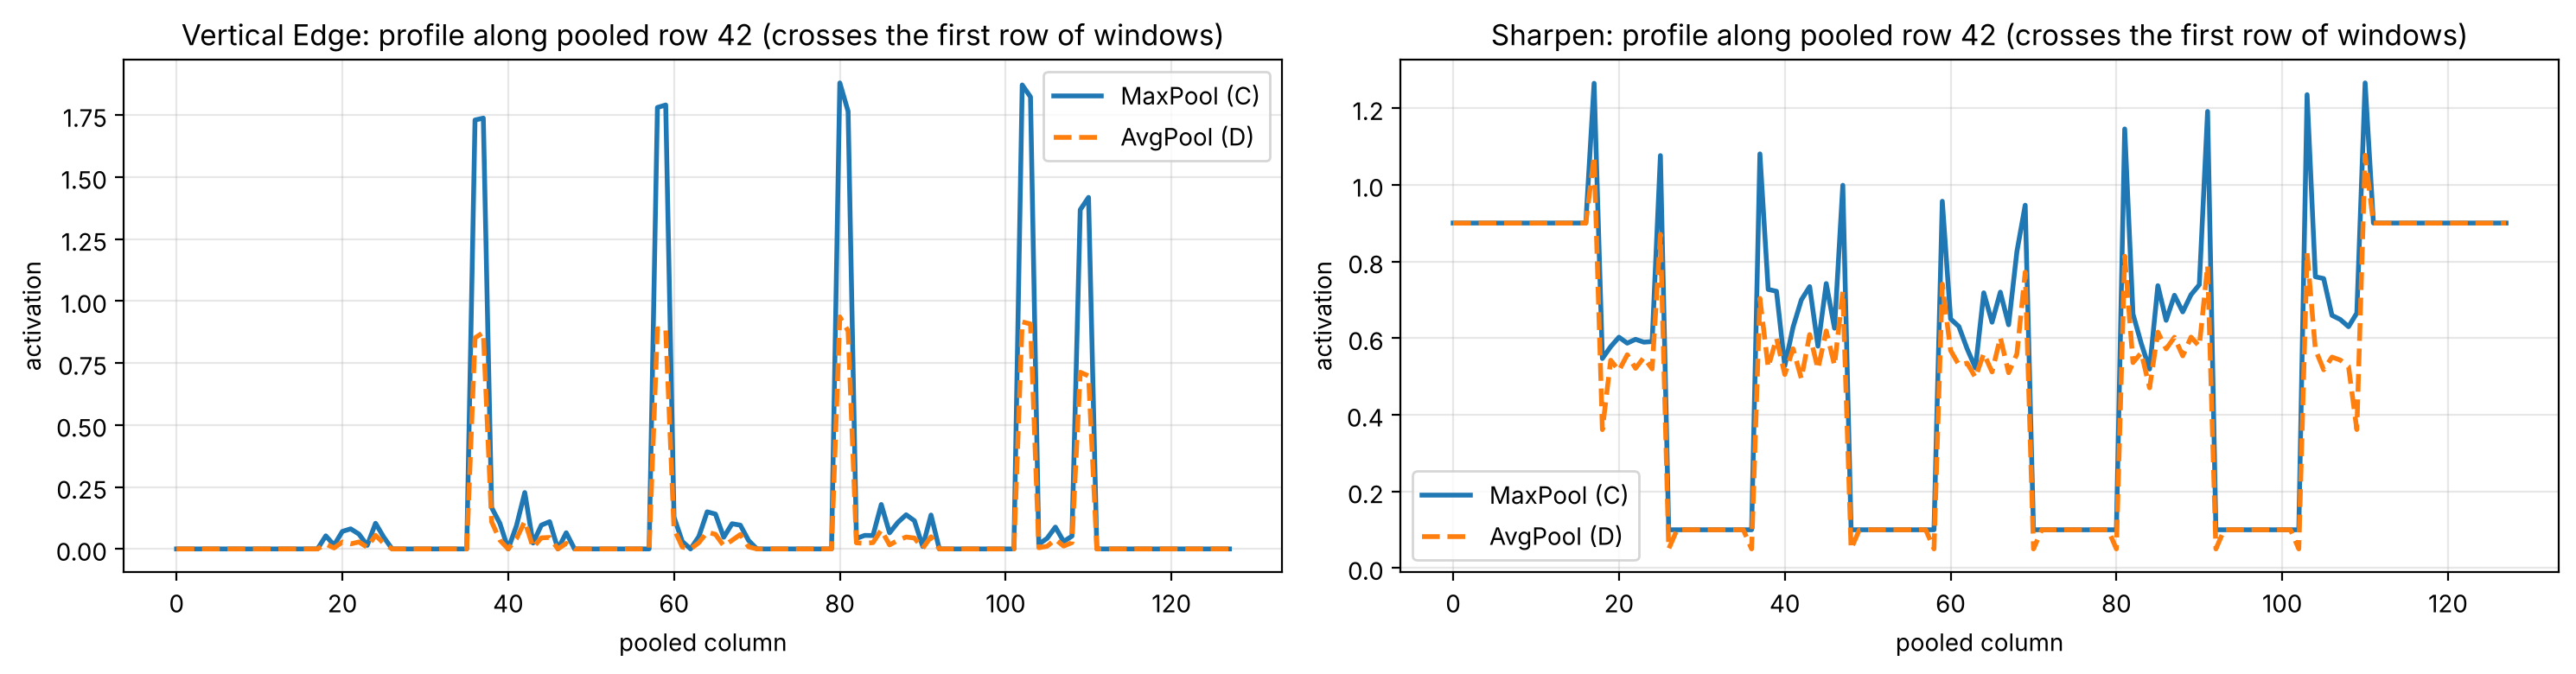

,Peak B,Peak C (max),Peak D (avg),Peak kept by Avg %,HF energy C,HF energy D,Edge px > 0.5·peak (C),Edge px > 0.5·peak (D)
Filter,,,,,,,,
Sharpen,1.5693,1.5693,1.2023,76.6131,0.2286,0.1658,7862,7060
Horizontal Edge,1.9216,1.9216,0.9893,51.4809,0.1322,0.0664,264,4
Vertical Edge,1.9458,1.9458,0.9856,50.6501,0.1745,0.0877,532,4
Emboss,2.0942,2.0942,1.4689,70.1401,0.2151,0.1442,796,413


In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 13))
for i, name in enumerate(["Sharpen", "Horizontal Edge", "Vertical Edge"]):
    C, D = stages[name]["C"], stages[name]["D"]; m = stages[name]["B"].max()
    for j, (t, X, cmap, lo, hi) in enumerate([("C: MaxPool", C, "gray", 0, m),
                                               ("D: AvgPool", D, "gray", 0, m),
                                               ("C − D (what Avg loses)", C - D, "magma", 0, m)]):
        im = axes[i, j].imshow(X, cmap=cmap, vmin=lo, vmax=hi)
        axes[i, j].set_title(f"{name}: {t}"); axes[i, j].axis("off")
        fig.colorbar(im, ax=axes[i, j], fraction=0.046)
plt.suptitle("Q2: Max vs Average pooling on the post-ReLU maps (same scale per row)", fontsize=14)
plt.tight_layout(); plt.savefig(f"{OUT}/q2_max_vs_avg_maps.png", dpi=150, bbox_inches="tight"); plt.show()

# 1-D intensity profile through the first window row (pooled row 42 = original rows 84-85)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, name in zip(axes, ["Vertical Edge", "Sharpen"]):
    ax.plot(stages[name]["C"][42], label="MaxPool (C)", lw=2)
    ax.plot(stages[name]["D"][42], label="AvgPool (D)", lw=2, ls="--")
    ax.set_title(f"{name}: profile along pooled row 42 (crosses the first row of windows)")
    ax.set_xlabel("pooled column"); ax.set_ylabel("activation"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/q2_profile.png", dpi=150, bbox_inches="tight"); plt.show()

def hf_energy(x):   # mean |Laplacian| = how much high-frequency detail survives
    return np.abs(conv_same(x, np.array([[0,1,0],[1,-4,1],[0,1,0]], np.float32))).mean()

q2 = pd.DataFrame([{
    "Filter": n,
    "Peak B": stages[n]["B"].max(),
    "Peak C (max)": stages[n]["C"].max(), "Peak D (avg)": stages[n]["D"].max(),
    "Peak kept by Avg %": 100 * stages[n]["D"].max() / stages[n]["B"].max(),
    "HF energy C": hf_energy(stages[n]["C"]), "HF energy D": hf_energy(stages[n]["D"]),
    "Edge px > 0.5·peak (C)": int((stages[n]["C"] > 0.5 * stages[n]["B"].max()).sum()),
    "Edge px > 0.5·peak (D)": int((stages[n]["D"] > 0.5 * stages[n]["B"].max()).sum()),
} for n in ["Sharpen", "Horizontal Edge", "Vertical Edge", "Emboss"]]).set_index("Filter")
q2.to_csv(f"{OUT}/q2_pooling_metrics.csv"); q2

### Q2(b) experiment: dark ink text on a white background (pixels ≈ 255)

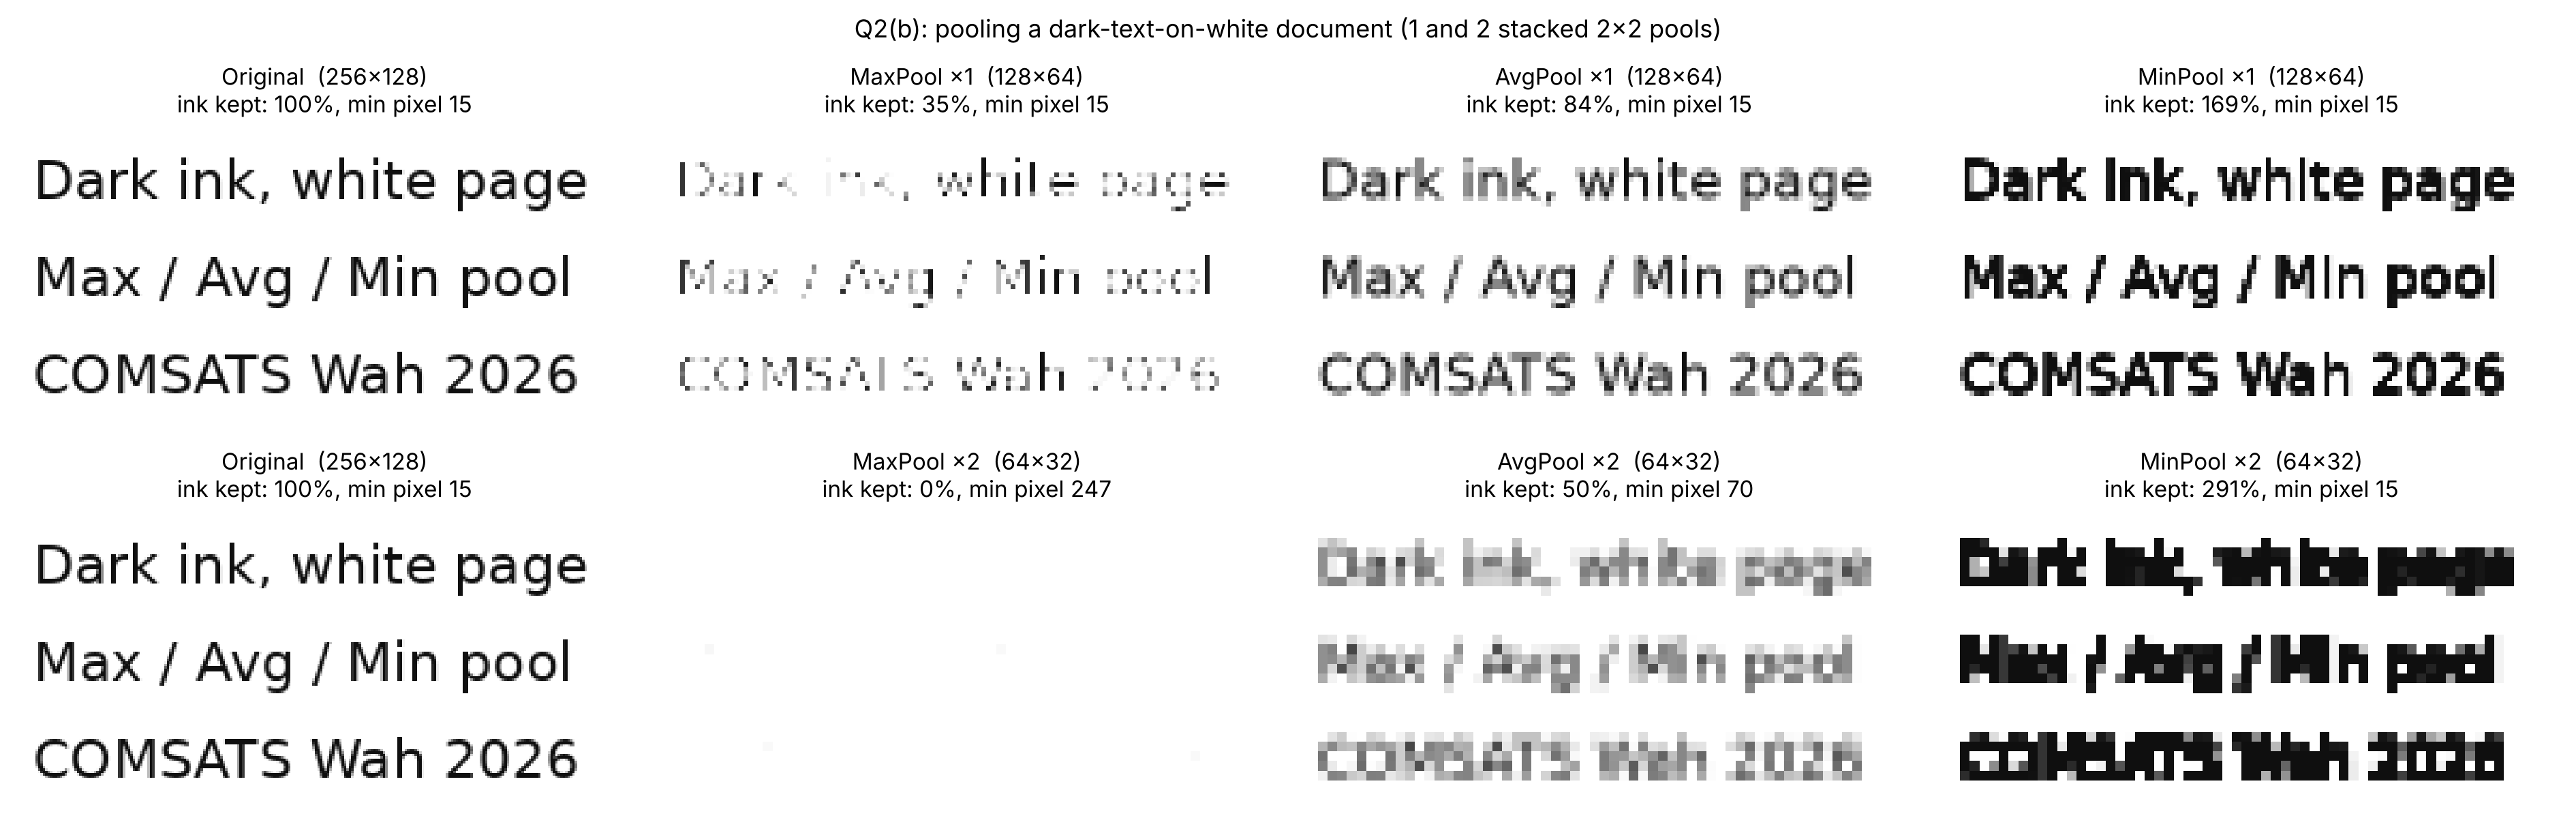

,Ink area kept %,Darkest pixel
Pooling,,
MaxPool ×1,34.6580,15.00
AvgPool ×1,84.4300,15.00
MinPool ×1,169.1205,15.00
MaxPool ×2,0.0000,247.00
AvgPool ×2,50.0326,70.25
MinPool ×2,291.3355,15.00


In [ ]:
font_path = fm.findfont("DejaVu Sans")
font = ImageFont.truetype(font_path, 22)
canvas = Image.new("L", (256, 128), 255)
d = ImageDraw.Draw(canvas)
d.text((8, 10),  "Dark ink, white page", fill=15, font=font)
d.text((8, 50),  "Max / Avg / Min pool", fill=15, font=font)
d.text((8, 90),  "COMSATS Wah 2026", fill=15, font=font)
text = np.asarray(canvas, np.float32)            # 0..255, text ≈ 15, paper = 255

def minpool(x): return -maxpool(-x)              # min-pool = max-pool on the negated image

def pool_n(f, x, n):
    for _ in range(n): x = f(x)
    return x

def ink_ratio(x, ref):                           # share of "ink" area (pixels < 128) relative to original
    return 100 * (x < 128).mean() / (ref < 128).mean()

fig, axes = plt.subplots(2, 4, figsize=(19, 6.5))
res = []
for r, n in enumerate([1, 2]):
    outs = [("Original", text), (f"MaxPool ×{n}", pool_n(maxpool, text, n)),
            (f"AvgPool ×{n}", pool_n(avgpool, text, n)), (f"MinPool ×{n}", pool_n(minpool, text, n))]
    for c, (t, X) in enumerate(outs):
        axes[r, c].imshow(X, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{t}  ({X.shape[1]}×{X.shape[0]})\nink kept: {ink_ratio(X, text):.0f}%, "
                             f"min pixel {X.min():.0f}")
        axes[r, c].axis("off")
        if c: res.append({"Pooling": t, "Ink area kept %": ink_ratio(X, text), "Darkest pixel": X.min()})
plt.suptitle("Q2(b): pooling a dark-text-on-white document (1 and 2 stacked 2×2 pools)", fontsize=13)
plt.tight_layout(); plt.savefig(f"{OUT}/q2_text_on_white.png", dpi=150, bbox_inches="tight"); plt.show()
pd.DataFrame(res).set_index("Pooling")

### ✍️ Answer Q2: Max vs Average pooling

**(a) What Max Pooling preserved and Average Pooling washed out** (`q2_max_vs_avg_maps.png`, `q2_profile.png`)

- **Thin edge lines (Horizontal and Vertical rows).** After ReLU each window edge is a line only 1–2 px wide. A 2×2 window that contains it holds **one or two strong values and the rest zeros**:
  - Max pooling returns the strong value, so the line keeps its **full peak (1.92 / 1.95)**.
  - Average pooling divides it by 4, so the peak drops to **0.99, i.e. ≈ 51 %**.
  - Counting pixels above half the peak: **264 vs 4** (Horizontal) and **532 vs 4** (Vertical). Under Avg pooling the window edges in columns C → D go from bright white to dull grey.
- **Sharpen row.** Max pooling keeps the **bright halos/rims around every window and around the building outline**, and also the **amplified wall texture (noise speckle)**. Average pooling smooths both. High-frequency energy (mean |Laplacian|) is **0.229 (max) vs 0.166 (avg)**, and Avg keeps only **77 %** of the sharpen peak.
- The `C − D` panel shows exactly what Average pooling throws away: it is bright **only on edges and texture**, and dark on flat regions such as the sky, the wall interior and the window glass.

Rule of thumb: **max pooling = "is the feature present anywhere in this 2×2 window?"** It keeps sparse, high-frequency detections. **Average pooling = "how much of the feature is here on average?"** It acts as a low-pass filter and dilutes isolated peaks.

**(b) Dark ink text on a white background (≈ 255)** (`q2_text_on_white.png`)

Here the information (ink ≈ 15) is the **minimum** of each window, and the background is the maximum.
- **Max pooling destroys the text.** Any 2×2 window that touches paper returns ≈ 255, so thin strokes are erased. Only **≈ 35 %** of the ink area survives one pool, and **0 %** survives two pools (the darkest remaining pixel is ≈ 247, i.e. blank paper).
- **Average pooling preserves the strokes better**: **≈ 84 %** after one pool and **≈ 50 %** after two. The strokes turn grey and slightly blurred but stay readable, because every ink pixel still pulls the average down.

➡️ Between the two, **Average pooling** is better for dark-on-light text. The ideal choice is **Min pooling** (= `−MaxPool(−x)`), or equivalently **inverting the image** (`255 − x`) so ink becomes the high value. That is why MNIST-style datasets store **white digits on black**: max pooling then keeps the strokes.

## Question 3: Parameter Explosion & Receptive Field Equivalence

In [ ]:
pA, pB = trainable(model_A), trainable(model_B)
convA = conv_params(3,3,3,5) + conv_params(3,3,5,10)
convB = conv_params(5,5,3,5) + conv_params(5,5,5,10)
print(f"Total params:      A = {pA},  B = {pB},  increase = {pB-pA}  ->  {100*(pB-pA)/pA:.2f}%")
print(f"Conv-only params:  A = {convA},  B = {convB},  increase = {convB-convA} -> {100*(convB-convA)/convA:.2f}%")
print(f"Per-weight ratio of a 5x5 vs 3x3 kernel: 25/9 = {25/9:.3f}  (+{100*(25/9-1):.1f}% weights, biases unchanged)\n")

# Receptive field of n stacked k×k stride-1 convs: RF = 1 + n·(k−1)
for n in range(1, 4):
    print(f"{n} stacked 3×3 conv(s) -> receptive field {1 + n*2}×{1 + n*2}")

# Empirical proof: push a single impulse through two 3×3 convs and see how far it spreads
impulse = np.zeros((15, 15), np.float32); impulse[7, 7] = 1
ones3 = np.ones((3, 3), np.float32)
two = tf.nn.conv2d(to4d(tf.nn.conv2d(to4d(impulse), ones3[..., None, None], 1, "SAME")[0, ..., 0].numpy()),
                   ones3[..., None, None], 1, "SAME")[0, ..., 0].numpy()
nz = np.argwhere(two > 0)
print("Impulse through two 3×3 convs touches a block of",
      np.ptp(nz[:, 0]) + 1, "×", np.ptp(nz[:, 1]) + 1, "pixels  ->  same RF as one 5×5")

Total params:      A = 710,  B = 1750,  increase = 1040  ->  146.48%
Conv-only params:  A = 600,  B = 1640,  increase = 1040 -> 173.33%
Per-weight ratio of a 5x5 vs 3x3 kernel: 25/9 = 2.778  (+177.8% weights, biases unchanged)

1 stacked 3×3 conv(s) -> receptive field 3×3
2 stacked 3×3 conv(s) -> receptive field 5×5
3 stacked 3×3 conv(s) -> receptive field 7×7
Impulse through two 3×3 convs touches a block of 5 × 5 pixels  ->  same RF as one 5×5


In [ ]:
rows = []
# (a) the textbook case: C -> C channels
for C in [5, 10, 64]:
    single = conv_params(5, 5, C, C)
    stacked = conv_params(3, 3, C, C) * 2
    rows.append({"Case": f"Generic {C}→{C} channels", "One 5×5": single, "Two 3×3": stacked,
                 "Saved": single - stacked, "Saved %": 100 * (single - stacked) / single})

# (b) applied to Model B's own layers (intermediate width = C_in, the cheapest valid choice)
c1_single, c1_stack = conv_params(5,5,3,5),  conv_params(3,3,3,3) + conv_params(3,3,3,5)
c2_single, c2_stack = conv_params(5,5,5,10), conv_params(3,3,5,5) + conv_params(3,3,5,10)
rows += [
    {"Case": "Model B Conv1 (3→5)  vs 3→3→5",  "One 5×5": c1_single, "Two 3×3": c1_stack,
     "Saved": c1_single - c1_stack, "Saved %": 100 * (c1_single - c1_stack) / c1_single},
    {"Case": "Model B Conv2 (5→10) vs 5→5→10", "One 5×5": c2_single, "Two 3×3": c2_stack,
     "Saved": c2_single - c2_stack, "Saved %": 100 * (c2_single - c2_stack) / c2_single},
]
rf = pd.DataFrame(rows).set_index("Case")

# Verify with Keras: Model B where each 5×5 conv is replaced by two 3×3 convs
model_B_stacked = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(3, 3, padding="same", activation="relu"), layers.Conv2D(5, 3, padding="same", activation="relu"),
    layers.AveragePooling2D(2, 2),
    layers.Conv2D(5, 3, padding="same", activation="relu"), layers.Conv2D(10, 3, padding="same", activation="relu"),
    layers.AveragePooling2D(2, 2),
    layers.GlobalAveragePooling2D(), layers.Dense(10, activation="softmax"),
], name="Model_B_with_stacked_3x3")
pBs = trainable(model_B_stacked)
print(f"Model B (5×5) = {pB} params | Model B rebuilt with stacked 3×3 = {pBs} params | "
      f"saved {pB - pBs} ({100*(pB-pBs)/pB:.1f}%), plus one extra ReLU per pair")
rf.to_csv(f"{OUT}/q3_receptive_field_savings.csv"); rf

Model B (5×5) = 1750 params | Model B rebuilt with stacked 3×3 = 1024 params | saved 726 (41.5%), plus one extra ReLU per pair


,One 5×5,Two 3×3,Saved,Saved %
Case,,,,
Generic 5→5 channels,630,460,170,26.9841
Generic 10→10 channels,2510,1820,690,27.4900
Generic 64→64 channels,102464,73856,28608,27.9200
Model B Conv1 (3→5) vs 3→3→5,380,224,156,41.0526
Model B Conv2 (5→10) vs 5→5→10,1260,690,570,45.2381


### ✍️ Answer Q3: parameter explosion and receptive field

**Percentage increase (Model A → Model B)**

$$\frac{1750 - 710}{710} \times 100 = \frac{1040}{710}\times 100 = \mathbf{146.48\%}$$

- Counting the convolution layers only: (1640 − 600) / 600 = **173.33 %**.
- Each kernel's weights grow by 25/9 = **2.78×** (+177.8 %). The total increase is smaller because the biases (15) and the Dense layer (110) do not change.

**Receptive field equivalence**

For stride-1 convolutions, RF = 1 + Σ(kᵢ − 1). One 3×3 gives 3×3, and two stacked 3×3 give 1 + 2 + 2 = **5×5**. So **2 stacked 3×3 layers** see exactly the same 5×5 region as one 5×5 layer. The notebook also checks this directly: an impulse pushed through two 3×3 convolutions spreads over a 5×5 block.

**Parameters saved**

| Case | One 5×5 | Two 3×3 | Saved |
|---|---|---|---|
| General C → C (with bias) | 25C² + C | 18C² + 2C | **7C² − C (≈ 28 %)** |
| C = 10 | 2 510 | 1 820 | **690 (27.5 %)** |
| Model B Conv1, 3→5 (as 3→3→5) | 380 | 224 | 156 |
| Model B Conv2, 5→10 (as 5→5→10) | 1 260 | 690 | 570 |
| **Whole Model B** (checked in Keras) | **1 750** | **1 024** | **726 (41.5 %)** |

The stacked version also adds an **extra ReLU**, which gives more non-linearity for the same receptive field. This is the VGG design argument.

⚠️ Viva caveat: the ≈ 28 % saving assumes the channel width stays the same. If the intermediate layer uses C_out channels and C_out > C_in (for example 5 → 10 → 10 = 460 + 910 = **1 370 > 1 260**), the stacked version can actually cost **more**. The width of the middle layer matters.

## Question 4: Operation Commutativity (Order Invariance)

In [ ]:
def mp2x2(p): return p.max()                       # max-pool of a single 2×2 window
P1 = np.array([[-3., -1.], [-2., -5.]])           # all negative
P2 = np.array([[-4.,  2.], [ 3., -6.]])           # mixed signs
for P in (P1, P2):
    a = mp2x2(np.maximum(P, 0))                    # Conv -> ReLU -> MaxPool
    b = max(mp2x2(P), 0)                           # Conv -> MaxPool -> ReLU
    print(f"patch {P.tolist()}:  ReLU→Max = {a},  Max→ReLU = {b},  equal: {a == b}")

print("\nCheck on all five real feature maps (256×256 → 128×128):")
for name, s in stages.items():
    order1 = maxpool(relu(s["A"]))
    order2 = relu(maxpool(s["A"]))
    print(f"  {name:16s} max |difference| = {np.abs(order1 - order2).max():.1e}  identical: {np.array_equal(order1, order2)}")

print("\nCounter-example: the swap is NOT valid for Average pooling:")
print(f"  patch {P2.tolist()}: ReLU→Avg = {np.maximum(P2,0).mean()},  Avg→ReLU = {max(P2.mean(),0)}")
H_, W_ = stages['Horizontal Edge']['A'].shape
print(f"\nReLU evaluations: before pooling = {H_*W_:,};  after pooling = {H_*W_//4:,}  (4× fewer)")

patch [[-3.0, -1.0], [-2.0, -5.0]]:  ReLU→Max = 0.0,  Max→ReLU = 0,  equal: True
patch [[-4.0, 2.0], [3.0, -6.0]]:  ReLU→Max = 3.0,  Max→ReLU = 3.0,  equal: True

Check on all five real feature maps (256×256 → 128×128):
  Horizontal Edge  max |difference| = 0.0e+00  identical: True
  Vertical Edge    max |difference| = 0.0e+00  identical: True
  Sharpen          max |difference| = 0.0e+00  identical: True
  Gaussian Blur    max |difference| = 0.0e+00  identical: True
  Emboss           max |difference| = 0.0e+00  identical: True

Counter-example: the swap is NOT valid for Average pooling:
  patch [[-4.0, 2.0], [3.0, -6.0]]: ReLU→Avg = 1.25,  Avg→ReLU = 0

ReLU evaluations: before pooling = 65,536;  after pooling = 16,384  (4× fewer)


### ✍️ Answer Q4: Conv → ReLU → MaxPool vs Conv → MaxPool → ReLU

**The outputs are identical**, for every pixel and every filter. The notebook confirms this on all five real feature maps: the maximum absolute difference is **0.0**.

**Proof.** ReLU(x) = max(0, x) is **monotonically non-decreasing**, so for any 2×2 window {x₁, x₂, x₃, x₄}:

$$\max_i\big(\max(0, x_i)\big) = \max\big(0, \max_i x_i\big)$$

Both sides are just the largest of {0, x₁, x₂, x₃, x₄}: the outer max of a max can be taken in any order.

| Patch | Conv → ReLU → MaxPool | Conv → MaxPool → ReLU |
|---|---|---|
| `[[-3, -1], [-2, -5]]` (all negative) | ReLU → `[[0,0],[0,0]]` → max = **0** | max = −1 → ReLU = **0** |
| `[[-4, 2], [3, -6]]` (mixed) | ReLU → `[[0,2],[3,0]]` → max = **3** | max = 3 → ReLU = **3** |

**Efficiency implication.** Pooling first means ReLU runs on a **4× smaller tensor**: 16 384 instead of 65 536 evaluations per channel here, with the same result. That is a free saving at inference time, although modern frameworks often fuse these operations anyway.

**Limits of the swap (good viva point):**
- It does **not** hold for **Average pooling**. For `[[-4,2],[3,-6]]`, ReLU→Avg = (0+2+3+0)/4 = **1.25**, but Avg→ReLU = max(0, −1.25) = **0**.
- It does not hold for **non-monotonic activations** such as GELU or Swish.
- It holds for any monotone non-decreasing activation (Leaky ReLU, sigmoid, tanh) combined with max pooling.

## Question 5: Diagnosing Filter Redundancy (Debugging Scenario)
Experiment: train the same small CNN for **20 epochs** on a synthetic 10-class oriented-grating dataset (it is generated in code, so nothing needs downloading), under three settings:
1. **Healthy**: He-normal weights, zero bias, Adam (lr = 1e-3)
2. **Root cause 1, symmetric initialisation**: every weight in the network starts from the same constant, so all filters get identical gradients
3. **Root cause 2, dead ReLUs**: a large negative bias (−5) pushes every pre-activation below 0 (a too-high learning rate can do the same during training)

Collapse metrics: the **mean pairwise correlation between the 5 Layer-1 feature maps** and the **mean pairwise cosine similarity between the 5 filter weight vectors**. A value of 1.0 means identical (two all-zero dead maps also count as identical). "Dead" means a filter outputs exactly 0 for every input.

In [ ]:
def make_gratings(n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:32, 0:32]
    X = np.zeros((n, 32, 32, 3), np.float32); y = rng.integers(0, 10, n)
    for i in range(n):
        th = y[i] * np.pi / 10 + rng.normal(0, 0.05)
        g = 0.5 + 0.5 * np.sin(0.6 * (xx * np.cos(th) + yy * np.sin(th)) + rng.uniform(0, 2*np.pi))
        X[i] = (g[..., None] * rng.uniform(0.6, 1.0, 3) + rng.normal(0, 0.05, (32, 32, 3))).clip(0, 1)
    return X, y
Xtr, ytr = make_gratings()

def small_cnn(k_init="he_normal", b_init="zeros", act="relu", symmetric=False):
    tf.keras.utils.set_random_seed(SEED)
    # symmetric=True: EVERY layer starts from the same constant, so no filter can ever differ from the others
    k2 = tf.keras.initializers.Constant(0.05) if symmetric else "he_normal"
    kd = tf.keras.initializers.Constant(0.05) if symmetric else "glorot_uniform"
    return models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(5, 3, padding="same", kernel_initializer=k_init, bias_initializer=b_init, name="conv1"),
        layers.LeakyReLU(negative_slope=0.1, name="act1") if act == "leaky" else layers.Activation(act, name="act1"),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(10, 3, padding="same", activation="relu", kernel_initializer=k2),
        layers.MaxPooling2D(2, 2),
        layers.GlobalAveragePooling2D(), layers.Dense(10, activation="softmax", kernel_initializer=kd),
    ])

def pairwise_mean(M, zero_rows):
    # mean over the 10 filter pairs; two all-zero (dead) maps count as identical (1), dead vs alive as 0
    vals = []
    for i in range(5):
        for j in range(i + 1, 5):
            if zero_rows[i] and zero_rows[j]: vals.append(1.0)
            elif zero_rows[i] or zero_rows[j]: vals.append(0.0)
            else: vals.append(float(np.clip(M[i, j], -1, 1)))
    return float(np.mean(vals))

def collapse_report(model, X):
    fmap = models.Model(model.inputs, model.get_layer("act1").output)(X[:64]).numpy()   # (64,32,32,5)
    F = fmap.transpose(3, 0, 1, 2).reshape(5, -1)
    dead = np.abs(F).max(axis=1) == 0
    Fc = F - F.mean(axis=1, keepdims=True)                       # centre -> Pearson correlation
    Fn = Fc / np.maximum(np.linalg.norm(Fc, axis=1, keepdims=True), 1e-12)
    sim = pairwise_mean(Fn @ Fn.T, dead)
    W = model.get_layer("conv1").get_weights()[0].reshape(-1, 5).T
    Wn = W / np.maximum(np.linalg.norm(W, axis=1, keepdims=True), 1e-12)
    wsim = pairwise_mean(Wn @ Wn.T, np.zeros(5, bool))
    return fmap, sim, wsim, int(dead.sum())

configs = {
    "Healthy (He init)":                dict(k_init="he_normal", b_init="zeros"),
    "Cause 1: constant (symmetric) init": dict(k_init=tf.keras.initializers.Constant(0.05), b_init="zeros", symmetric=True),
    "Cause 2: dead ReLU (bias −5)":     dict(k_init="he_normal", b_init=tf.keras.initializers.Constant(-5.0)),
    "Fix 2: LeakyReLU + same bias −5":  dict(k_init="he_normal", b_init=tf.keras.initializers.Constant(-5.0),
                                             act="leaky"),
}
results, fmaps = [], {}
for name, cfg in configs.items():
    m = small_cnn(**cfg)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = m.fit(Xtr, ytr, epochs=20, batch_size=64, verbose=0, validation_split=0.2)
    fmap, sim, wsim, dead = collapse_report(m, Xtr)
    fmaps[name] = fmap
    results.append({"Setting": name, "Val accuracy (ep 20)": h.history["val_accuracy"][-1],
                    "Feature-map correlation": sim, "Filter-weight cosine sim": wsim, "Dead filters / 5": dead})
q5 = pd.DataFrame(results).set_index("Setting"); q5.to_csv(f"{OUT}/q5_filter_collapse.csv"); q5

,Val accuracy (ep 20),Feature-map correlation,Filter-weight cosine sim,Dead filters / 5
Setting,,,,
Healthy (He init),0.9900,0.7134,0.3019,0
Cause 1: constant (symmetric) init,0.1150,1.0000,1.0000,0
Cause 2: dead ReLU (bias −5),0.0900,1.0000,0.0027,5
Fix 2: LeakyReLU + same bias −5,0.9775,0.1635,0.0418,0


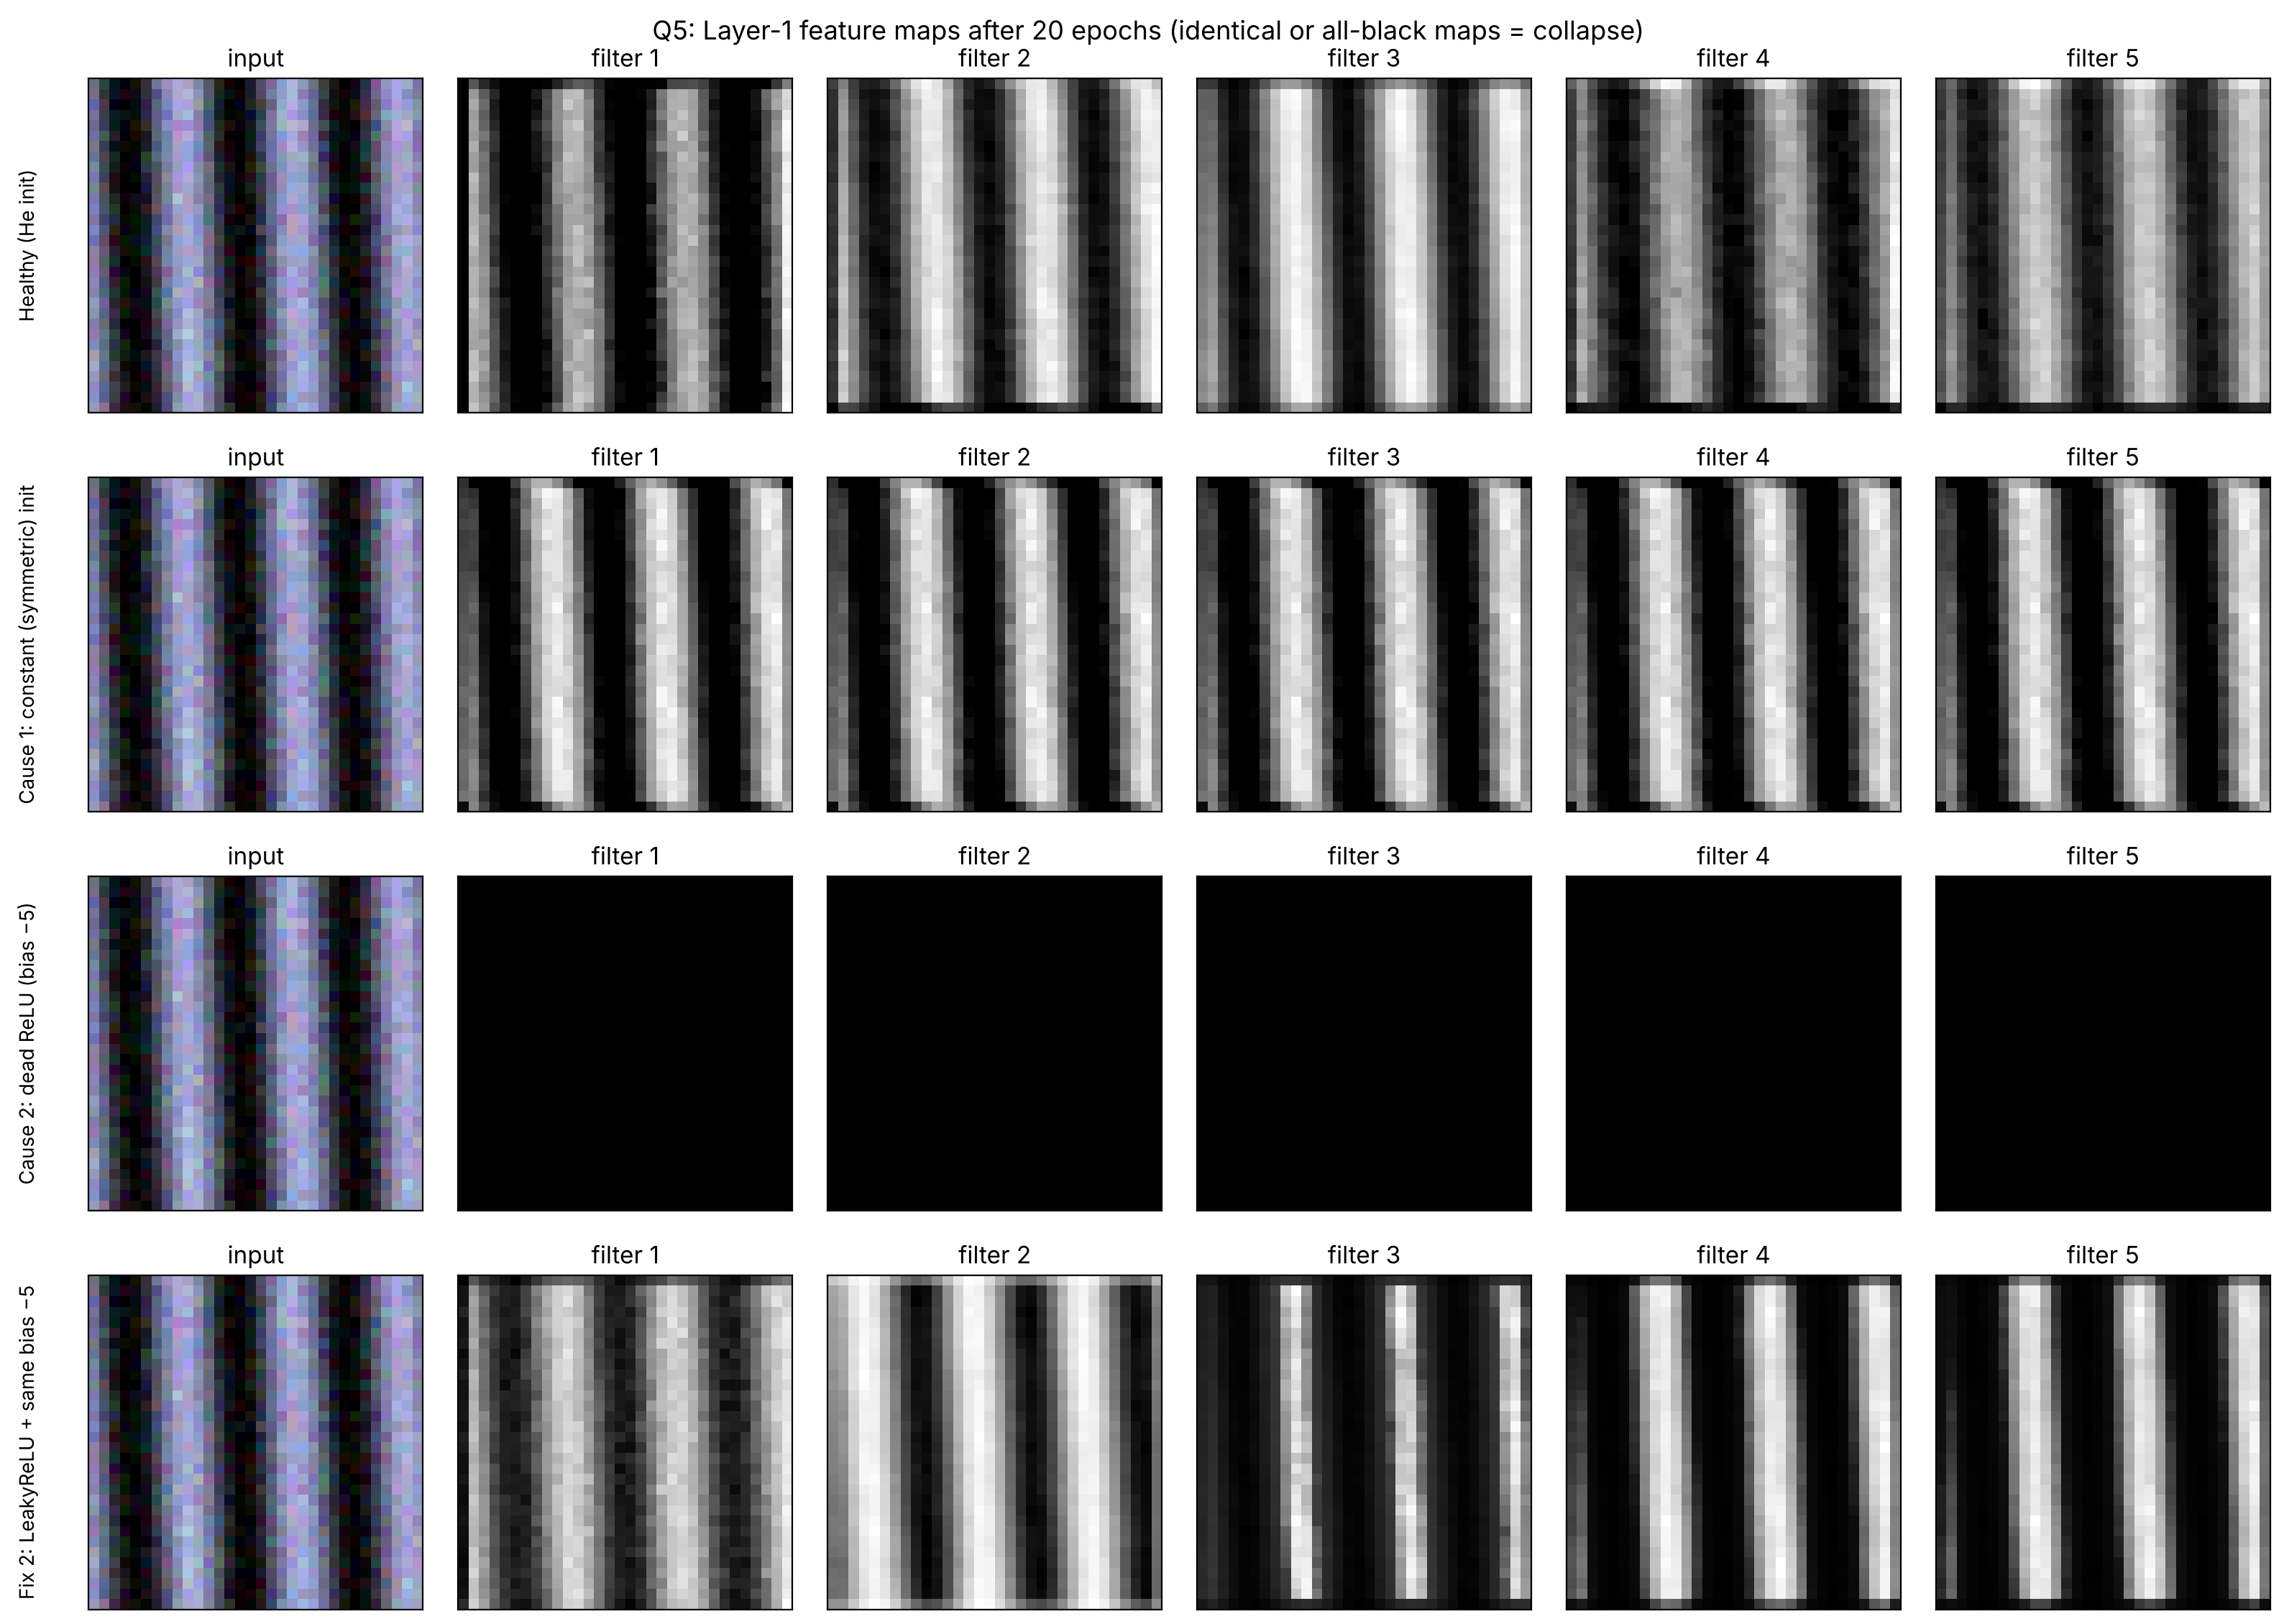

In [ ]:
fig, axes = plt.subplots(len(fmaps), 6, figsize=(16, 2.9 * len(fmaps)))
for r, (name, fm_) in enumerate(fmaps.items()):
    axes[r, 0].imshow(Xtr[0]); axes[r, 0].set_title("input")
    for f in range(5):
        axes[r, f + 1].imshow(fm_[0, ..., f], cmap="gray"); axes[r, f + 1].set_title(f"filter {f+1}")
    for ax in axes[r]: ax.set_xticks([]); ax.set_yticks([])
    axes[r, 0].text(-0.15, 0.5, name, transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=10)
plt.suptitle("Q5: Layer-1 feature maps after 20 epochs (identical or all-black maps = collapse)", fontsize=13)
plt.tight_layout(); plt.savefig(f"{OUT}/q5_filter_collapse.png", dpi=150, bbox_inches="tight"); plt.show()

### ✍️ Answer Q5: diagnosing filter collapse (all 5 Layer-1 filters look identical)

| Setting (20 epochs) | Val acc | Feature-map correlation | Filter-weight cos-sim | Dead filters |
|---|---|---|---|---|
| Healthy (He init) | ≈ 0.99 | ≈ 0.71 | ≈ 0.30 | 0 |
| **Cause 1: constant / symmetric init** | **≈ 0.12** (chance = 0.10) | **1.00** | **1.00** | 0 |
| **Cause 2: dead ReLUs (bias −5)** | **≈ 0.09** | **1.00** (all black) | ≈ 0.00 (random but frozen) | **5 / 5** |
| Fix 2: Leaky ReLU, same bias | ≈ 0.98 | ≈ 0.16 | ≈ 0.04 | 0 |

(The table printed above has the exact values from your run.)

**Root cause 1: symmetric weight initialisation (e.g. all zeros or one constant).**
If every filter starts with the same weights, every filter produces the same output, so every filter gets **exactly the same gradient**. After the update they are still identical, and this repeats every step. Gradient descent can never break the symmetry, so after 20 epochs the 5 filters are still copies of each other (cos-sim = 1.00). The network effectively has **one** filter, and accuracy stays at chance.
**Fix:** use **random, variance-scaled initialisation**: **He/Kaiming normal** for ReLU layers (`kernel_initializer="he_normal"`), or Glorot/Xavier for tanh/sigmoid. Never initialise weights to zero or a constant; biases can safely start at 0. In the experiment this brings correlation down to 0.71 (similar but not identical maps, because the dataset is simple) and accuracy up to 99 %.

**Root cause 2: dead ReLUs (from a learning rate that is too high, or a large negative bias).**
If a big update pushes a filter's bias or weights so that its pre-activation is **< 0 for every input**, ReLU outputs 0 everywhere and its gradient is also 0. The filter is **dead** and can never recover. All dead filters produce the **same all-black map**, which looks exactly like "nearly identical feature maps". In the experiment all **5 / 5** filters died and accuracy fell to chance.
**Fix:** use **Leaky ReLU / PReLU / ELU**, so the negative side still has a small gradient (with the same −5 bias, Leaky ReLU recovered to 0 dead filters and 98 % accuracy). Also **lower the learning rate** (or use warm-up / gradient clipping), start biases at 0, and add **Batch Normalization** after the convolution so pre-activations stay centred around 0.

Other contributors worth mentioning in the viva: very strong **L2 weight decay**, which shrinks all filters toward the same near-zero solution, and an **over-parameterised first layer** on a very simple dataset, where several filters legitimately learn the same edge detector. Monitoring the pairwise filter similarity and the percentage of dead units during training catches both problems early.

---
## Export everything
Run this cell in Colab to download every figure and CSV as a single zip, ready for your report.

In [ ]:
import shutil
shutil.make_archive("cnn_lab_outputs", "zip", OUT)
print(sorted(os.listdir(OUT)))
try:
    from google.colab import files
    files.download("cnn_lab_outputs.zip")
except ImportError:
    print("Not running in Colab: zip saved as cnn_lab_outputs.zip")

['00_input_image.png', '01_feature_grid_5x4.png', 'part1_stage_statistics.csv', 'part2_parameter_audit.csv', 'q1_activation_comparison.png', 'q1_relu_blackout_zoom.png', 'q2_max_vs_avg_maps.png', 'q2_pooling_metrics.csv', 'q2_profile.png', 'q2_text_on_white.png', 'q3_receptive_field_savings.csv', 'q5_filter_collapse.csv', 'q5_filter_collapse.png']
Not running in Colab: zip saved as cnn_lab_outputs.zip
